# EDA

Daten Laden

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from packaging.version import Version

# scikit-learn < 1.9 bricht beim MLP mit early_stopping=True und Text-Labels ab (siehe requirements.txt)
assert Version(sklearn.__version__) >= Version('1.9'), f'scikit-learn >= 1.9 benötigt, installiert ist {sklearn.__version__}'

df = pd.read_csv('data/train.csv')
spec_cols = [c for c in df.columns if c.startswith('X')]
print('Shape:', df.shape)
print('Anzahl Spektralband-Spalten:', len(spec_cols))
print(df.head())

df['spectral_sum'] = df[spec_cols].sum(axis=1)
print(df['spectral_sum'])
df['spectral_sum'].describe()

Shape: (5591, 204)
Anzahl Spektralband-Spalten: 198
   Unnamed: 0  AEZ  Month  Crop     Stage  X427       X437       X447  \
0           0   10      8  corn  Critical   NaN  21.380647  19.123425   
1           1   10      8  corn  Critical   NaN  20.156616  18.015525   
2           2    8      8  corn  Critical   NaN  15.149693  13.715446   
3           3   10      8  corn  Critical   NaN  16.668828  14.892895   
4           4   10      7  corn  Critical   NaN  17.949177  16.185521   

        X457       X468  ...     X2315     X2325     X2335     X2345  X2355  \
0  17.686109  17.341397  ...  4.614991  4.159126  3.969469  4.008810    NaN   
1  16.671422  16.203317  ...  4.736217  4.596522  5.008663  5.293355    NaN   
2  13.172751  12.812346  ...  5.219686  4.235294  4.448717  5.725971    NaN   
3  13.907130  13.593934  ...  6.839068  6.024881  5.841306  5.888424    NaN   
4  15.237852  15.011519  ...  5.754674  5.626414  4.952164  4.013303    NaN   

   X2365  X2375  X2385  X2395     

/tmp/ipykernel_338/1603453920.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['spectral_sum'] = df[spec_cols].sum(axis=1)


count    5591.000000
mean     3489.585273
std       650.518608
min      1576.410873
25%      3020.378145
50%      3366.346749
75%      3917.899969
max      6630.957227
Name: spectral_sum, dtype: float64

mittlere Spektralsumme nach Crop und Stage untersucht

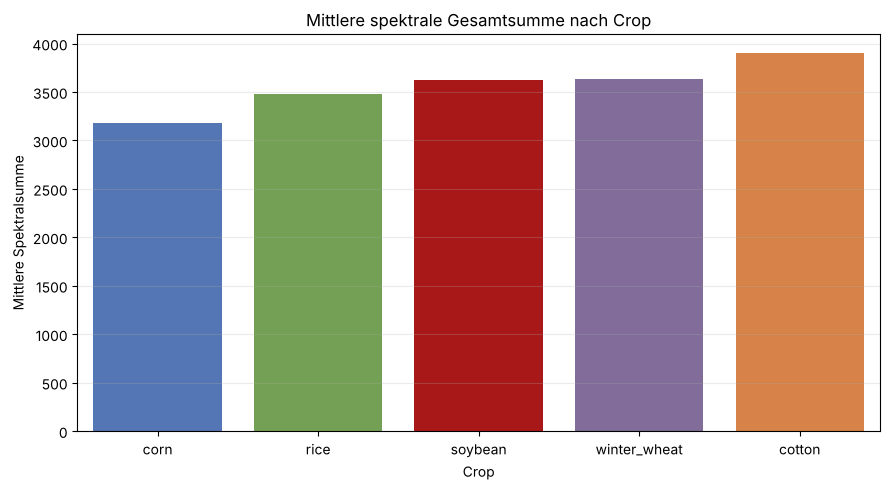

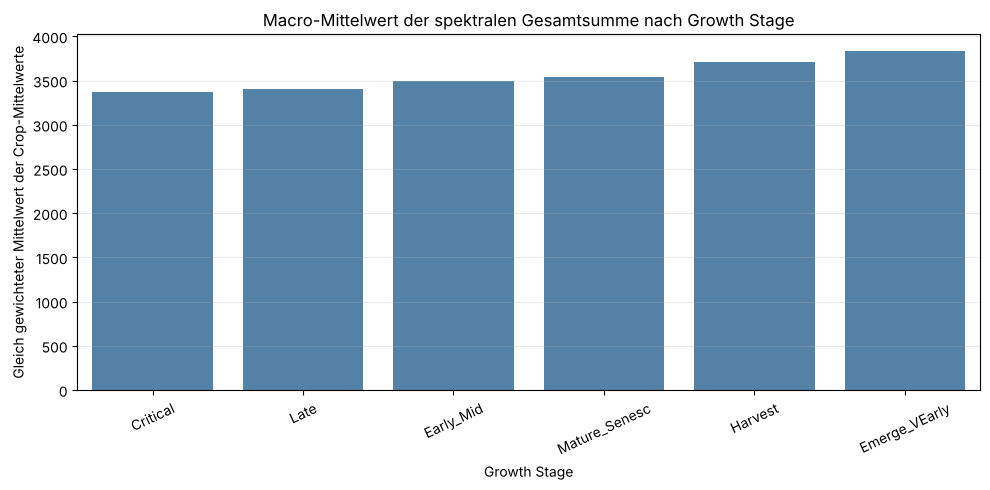

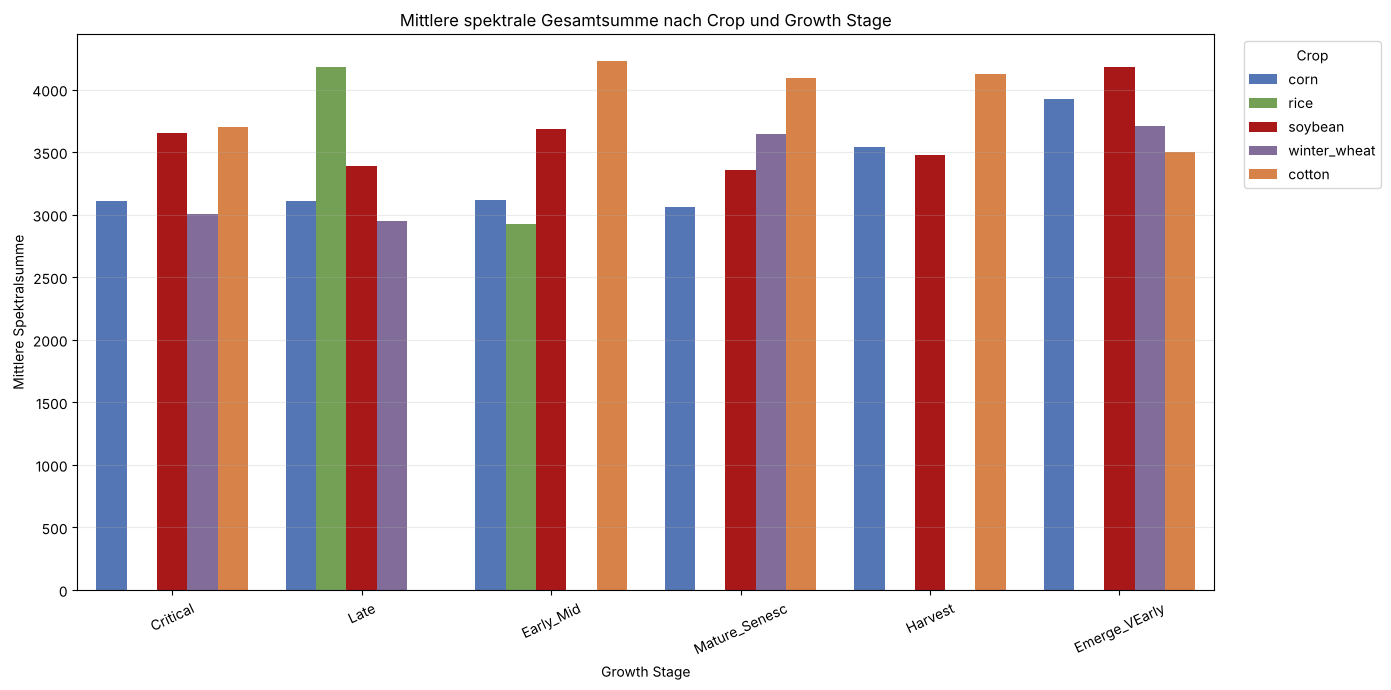

In [2]:
import seaborn as sns

# Einheitliche Farbzuordnung
palette = {
    'corn': '#4472C4',
    'cotton': '#ED7D31',
    'rice': '#70AD47',
    'soybean': '#C00000',
    'winter_wheat': '#8064A2'
}

# Sortierung aufsteigend nach Mittelwert
crop_order = (
    df.groupby('Crop')['spectral_sum']
    .mean()
    .sort_values(ascending=True)
    .index.tolist()
)

# Mittelwert je Crop und Stage
crop_stage_means = (
    df.groupby(['Crop', 'Stage'])['spectral_sum']
    .mean()
    .reset_index()
)

# Gleich gewichteter Mittelwert der Crop-Mittelwerte je Stage
stage_macro_means = (
    crop_stage_means.groupby('Stage')['spectral_sum']
    .mean()
)

# Sortierung der Stages nach Macro-Mittelwert
stage_order = (
    stage_macro_means
    .sort_values(ascending=True)
    .index.tolist()
)


# 1. Crops
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x='Crop',
    y='spectral_sum',
    order=crop_order,
    hue='Crop',
    hue_order=crop_order,
    palette=palette,
    errorbar=None,
    legend=False
)

plt.title('Mittlere spektrale Gesamtsumme nach Crop')
plt.xlabel('Crop')
plt.ylabel('Mittlere Spektralsumme')
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()


# 2. Stages – gleich gewichteter Mittelwert über Crops
plt.figure(figsize=(10, 5))

sns.barplot(
    x=stage_macro_means.index,
    y=stage_macro_means.values,
    order=stage_order,
    color='steelblue'
)

plt.title('Macro-Mittelwert der spektralen Gesamtsumme nach Growth Stage')
plt.xlabel('Growth Stage')
plt.ylabel('Gleich gewichteter Mittelwert der Crop-Mittelwerte')
plt.xticks(rotation=25)
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()


# 3. Crops und Stages gemeinsam
plt.figure(figsize=(14, 7))

sns.barplot(
    data=df,
    x='Stage',
    y='spectral_sum',
    hue='Crop',
    order=stage_order,
    hue_order=crop_order,
    palette=palette,
    errorbar=None
)

plt.title('Mittlere spektrale Gesamtsumme nach Crop und Growth Stage')
plt.xlabel('Growth Stage')
plt.ylabel('Mittlere Spektralsumme')
plt.xticks(rotation=25)

plt.legend(
    title='Crop',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

untersucht auf nan werte in den Spektralband-spalten

In [3]:
na_frac = df[spec_cols].isna().mean()
full_na = na_frac[na_frac == 1.0]
partial_na = na_frac[(na_frac > 0) & (na_frac < 1.0)]


print(f'Komplett leere Spektralband-Spalten: {len(full_na)} von {len(spec_cols)}')
print(f'Teilweise fehlende Spalten: {len(partial_na)}')
print('Max. Fehlanteil bei teilweise fehlenden Spalten:', round(partial_na.max() * 100, 2), '%')
print('Zeilen ohne jegliche NaN:', (df[spec_cols].isna().sum(axis=1) == 0).sum(), '/', len(df))

Komplett leere Spektralband-Spalten: 67 von 198
Teilweise fehlende Spalten: 6
Max. Fehlanteil bei teilweise fehlenden Spalten: 0.43 %
Zeilen ohne jegliche NaN: 0 / 5591


Untersucht, wie sich die durchschnittlichen Absorptionswerte Je Crop und je Band verhalten

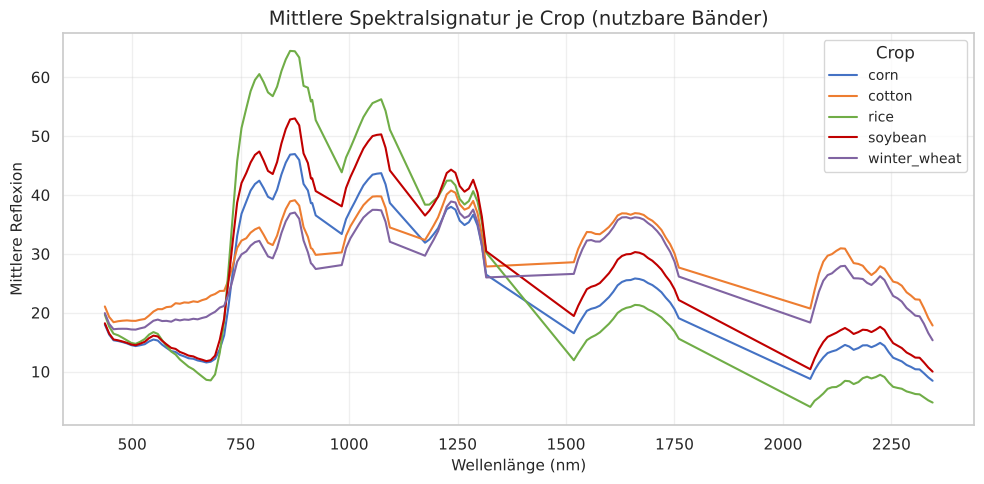

In [4]:
sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="colorblind",
    rc={
        "figure.figsize": (10, 5),
        "axes.titlesize": 14,
        "axes.labelsize": 11,
        "legend.fontsize": 10,
        "axes.grid": True,
        "grid.alpha": 0.25
    }
)

crop_palette = {
    "corn": "#4472C4",
    "cotton": "#ED7D31",
    "rice": "#70AD47",
    "soybean": "#C00000",
    "winter_wheat": "#8064A2"
}

stage_palette = {
    "Critical": "#4472C4",
    "Early_Mid": "#ED7D31",
    "Emerge_VEarly": "#70AD47",
    "Harvest": "#C00000",
    "Late": "#8064A2",
    "Mature_Senesc": "#A5A5A5"
}

usable_cols = [c for c in spec_cols if c not in full_na.index]
wavelengths = [int(c[1:]) for c in usable_cols]
order = np.argsort(wavelengths)
wavelengths_sorted = np.array(wavelengths)[order]
usable_sorted = np.array(usable_cols)[order]

plt.figure(figsize=(10, 5))
for crop, group in df.groupby('Crop'):
    mean_signature = group[usable_sorted].mean()
    plt.plot(
        wavelengths_sorted,
        mean_signature.values,
        label=crop,
        color=crop_palette[crop]
    )
plt.xlabel('Wellenlänge (nm)')
plt.ylabel('Mittlere Reflexion')
plt.title('Mittlere Spektralsignatur je Crop (nutzbare Bänder)')
plt.legend(title='Crop')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Crop und Stage Verteilung

In [5]:
print('Crop-Verteilung:')
display(df['Crop'].value_counts())
print('\nStage-Verteilung:')
display(df['Stage'].value_counts())
print('\nKreuztabelle Crop x Stage:')
pd.crosstab(df['Crop'], df['Stage'])

Crop-Verteilung:


Crop
corn            2097
soybean         1669
winter_wheat    1073
cotton           659
rice              93
Name: count, dtype: int64


Stage-Verteilung:


Stage
Critical         1541
Emerge_VEarly    1038
Mature_Senesc     989
Early_Mid         982
Late              861
Harvest           180
Name: count, dtype: int64


Kreuztabelle Crop x Stage:


Stage,Critical,Early_Mid,Emerge_VEarly,Harvest,Late,Mature_Senesc
Crop,,,,,,
corn,675,212,152,102,557,399
cotton,158,253,172,11,0,65
rice,0,52,0,0,41,0
soybean,652,465,106,67,233,146
winter_wheat,56,0,608,0,30,379


Trennschärfe der Bänder analysieren

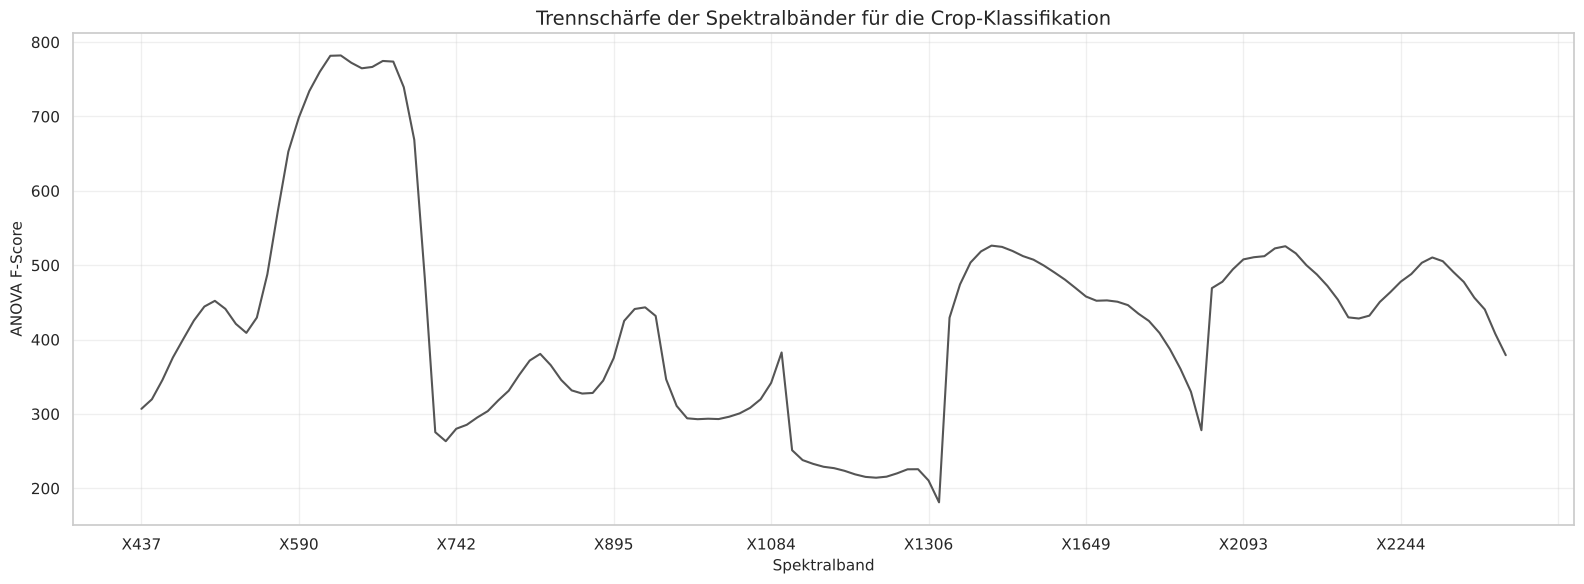

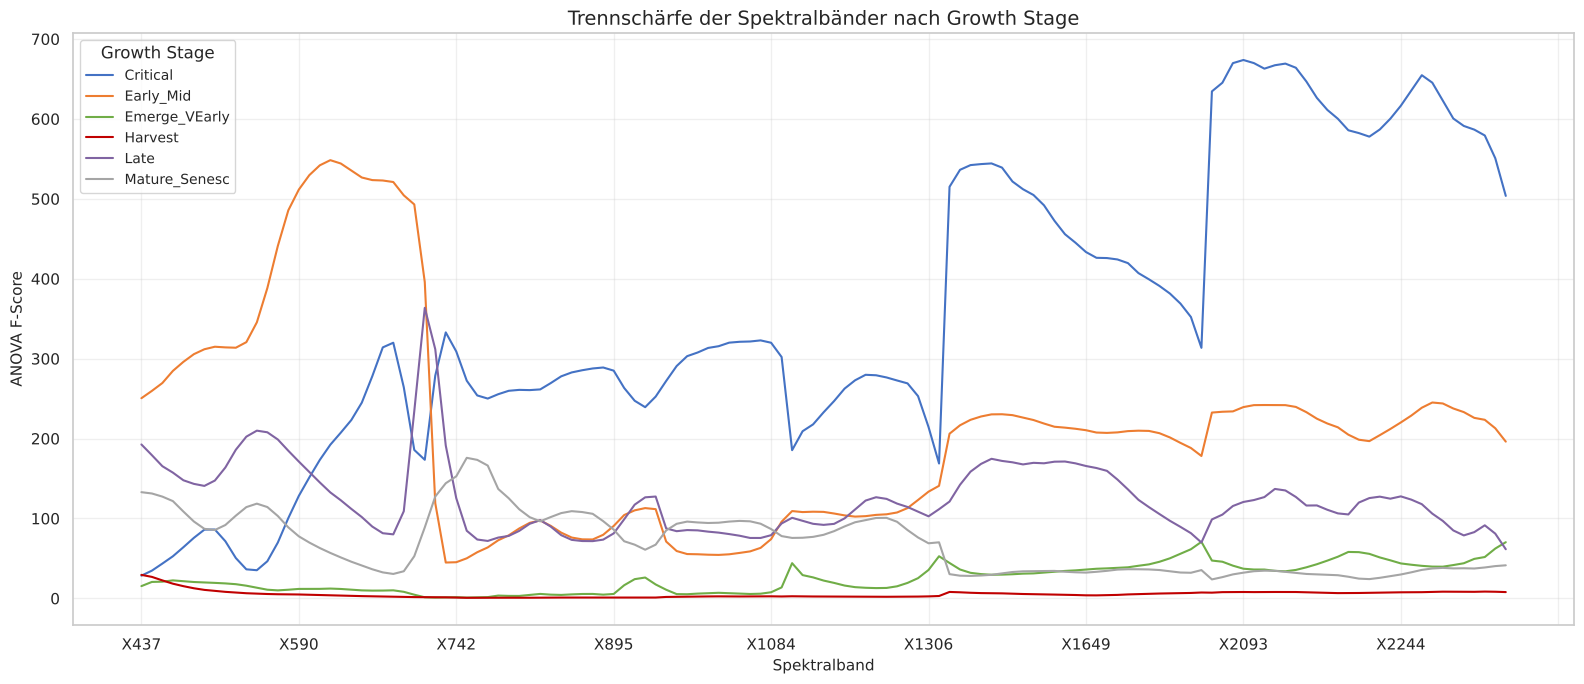

In [6]:
from sklearn.feature_selection import f_classif
from matplotlib.ticker import MaxNLocator

# Vollständig leere Spektralbänder entfernen
X = df[spec_cols].dropna(axis=1, how='all')

# Fehlende Werte mit dem jeweiligen Bandmittelwert ersetzen
X_filled = X.fillna(X.mean())

# F-Score berechnen
f_scores, p_values = f_classif(X_filled, df['Crop'])

score_df = pd.DataFrame({
    'Band': X.columns,
    'F-Score': f_scores
})

# Plot
plt.figure(figsize=(16, 6))
plt.plot(score_df['Band'], score_df['F-Score'], color='#555555')

plt.title('Trennschärfe der Spektralbänder für die Crop-Klassifikation')
plt.xlabel('Spektralband')
plt.ylabel('ANOVA F-Score')

# Nur wenige Labels anzeigen
plt.gca().xaxis.set_major_locator(MaxNLocator(nbins=10))

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Vollständig leere Spektralbänder entfernen
X = df[spec_cols].dropna(axis=1, how='all')

stage_scores = {}

for stage in df['Stage'].unique():

    subset = df[df['Stage'] == stage]

    X_stage = subset[X.columns].copy()
    y_stage = subset['Crop']

    # Fehlende Werte mit dem jeweiligen Bandmittelwert ersetzen
    X_stage = X_stage.fillna(X_stage.mean())

    # F-Score je Band
    f_scores, _ = f_classif(X_stage, y_stage)

    stage_scores[stage] = f_scores

# Ergebnisse als DataFrame
score_stage_df = pd.DataFrame(
    stage_scores,
    index=X.columns
)

# Diagramm
plt.figure(figsize=(16, 7))

for stage in score_stage_df.columns:
    plt.plot(
        score_stage_df.index,
        score_stage_df[stage],
        label=stage,
        color=stage_palette[stage]
    )

plt.title('Trennschärfe der Spektralbänder nach Growth Stage')
plt.xlabel('Spektralband')
plt.ylabel('ANOVA F-Score')

# Nur wenige Labels anzeigen
plt.gca().xaxis.set_major_locator(MaxNLocator(nbins=10))

plt.legend(title='Growth Stage')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Aufgrund des Anova F-Scores die Streuung genauer analysiert

In [7]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Vollständig leere Bänder entfernen
valid_bands = [
    c for c in spec_cols
    if df[c].notna().any()
]

# Wellenlängen aus den Spaltennamen extrahieren
wavelengths = np.array([
    int(c[1:]) for c in valid_bands
])

crops = sorted(df["Crop"].dropna().unique())

fig = make_subplots(
    rows=2,
    cols=1,
    shared_xaxes=True,
    vertical_spacing=0.12,
    row_heights=[0.72, 0.28],
    subplot_titles=[
        "Spektrale Signatur und Variabilität",
        "Streuung innerhalb der Crop-Klassen (Q90 − Q10)"
    ]
)

for crop in crops:

    data = df.loc[df["Crop"] == crop, valid_bands]

    q10 = data.quantile(0.10).to_numpy()
    q50 = data.quantile(0.50).to_numpy()
    q90 = data.quantile(0.90).to_numpy()

    color = crop_palette.get(crop, "#777777")

    # Obere Grenze des Quantilbands
    fig.add_trace(
        go.Scatter(
            x=wavelengths,
            y=q90,
            mode="lines",
            line=dict(width=0),
            showlegend=False,
            hoverinfo="skip",
            legendgroup=crop,
            connectgaps=False
        ),
        row=1, col=1
    )

    # Untere Grenze + gefülltes Quantilband
    fig.add_trace(
        go.Scatter(
            x=wavelengths,
            y=q10,
            mode="lines",
            line=dict(width=0),
            fill="tonexty",
            fillcolor=color,
            opacity=0.16,
            showlegend=False,
            hoverinfo="skip",
            legendgroup=crop,
            connectgaps=False
        ),
        row=1, col=1
    )

    # Median
    fig.add_trace(
        go.Scatter(
            x=wavelengths,
            y=q50,
            mode="lines",
            name=crop,
            line=dict(color=color, width=2.5),
            legendgroup=crop,
            connectgaps=False,
            hovertemplate=(
                f"<b>{crop}</b><br>"
                "Wellenlänge: %{x} nm<br>"
                "Median: %{y:.2f}<extra></extra>"
            )
        ),
        row=1, col=1
    )

    # Quantilbreite
    fig.add_trace(
        go.Scatter(
            x=wavelengths,
            y=q90 - q10,
            mode="lines",
            name=crop,
            line=dict(color=color, width=2),
            legendgroup=crop,
            showlegend=False,
            connectgaps=False,
            hovertemplate=(
                f"<b>{crop}</b><br>"
                "Wellenlänge: %{x} nm<br>"
                "Q90 − Q10: %{y:.2f}<extra></extra>"
            )
        ),
        row=2, col=1
    )

fig.update_layout(
    title="Hyperspektrale Verteilung nach Pflanzenart",
    template="plotly_white",
    height=850,
    hovermode="x",
    legend=dict(
        title="Crop – Klick zum Ein-/Ausblenden",
        groupclick="togglegroup"
    ),
    margin=dict(l=70, r=40, t=100, b=70)
)

fig.update_xaxes(
    title_text="Wellenlänge / Band",
    row=2, col=1
)

fig.update_yaxes(
    title_text="Reflektanz",
    rangemode="tozero",
    row=1, col=1
)

fig.update_yaxes(
    title_text="Quantilbreite",
    rangemode="tozero",
    row=2, col=1
)

fig.show()

Einfluss von AEZ und Month auf Stage und Crop. Erkenntnis, AEZ ist relevant für Crop und Month für Stage. Was auch zu erwarten war

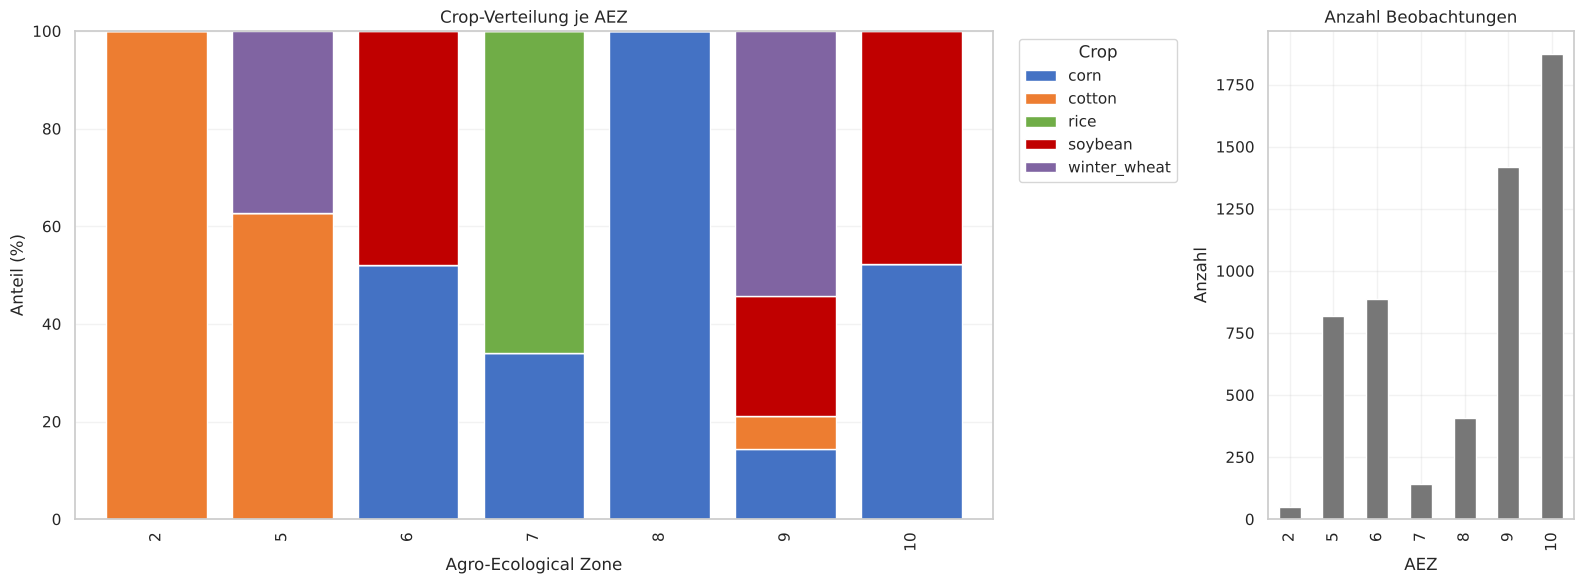

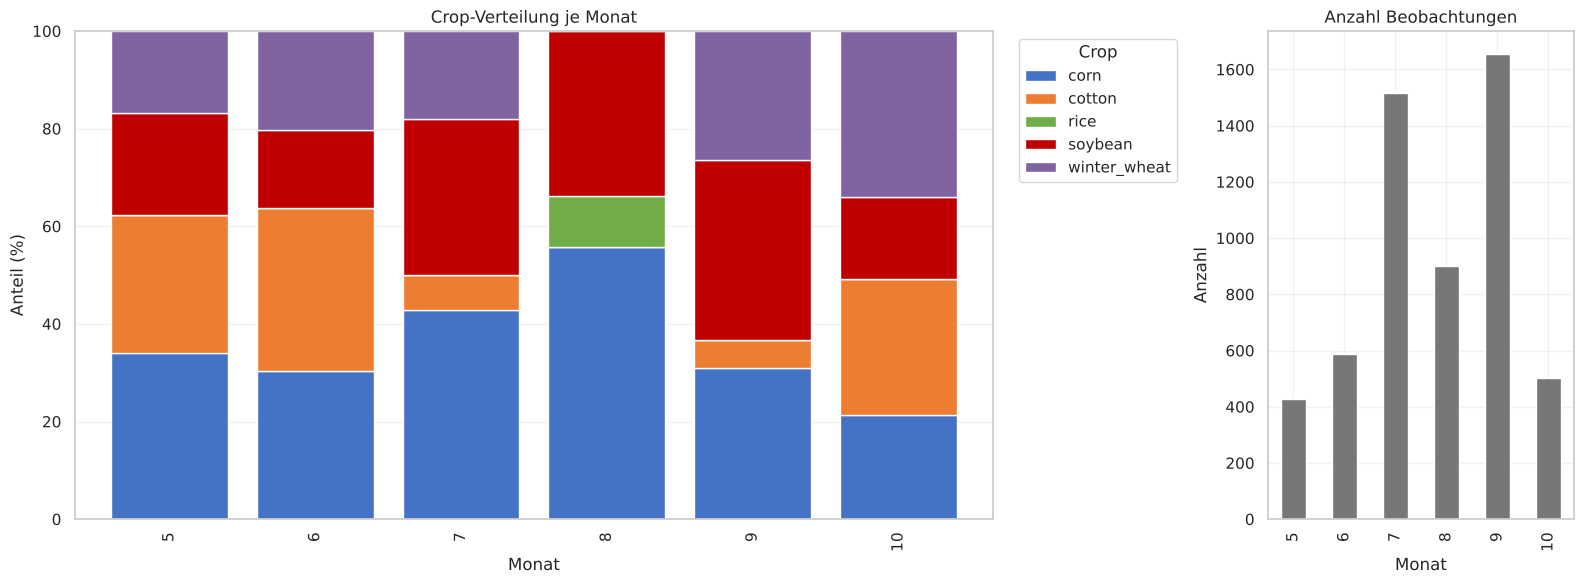

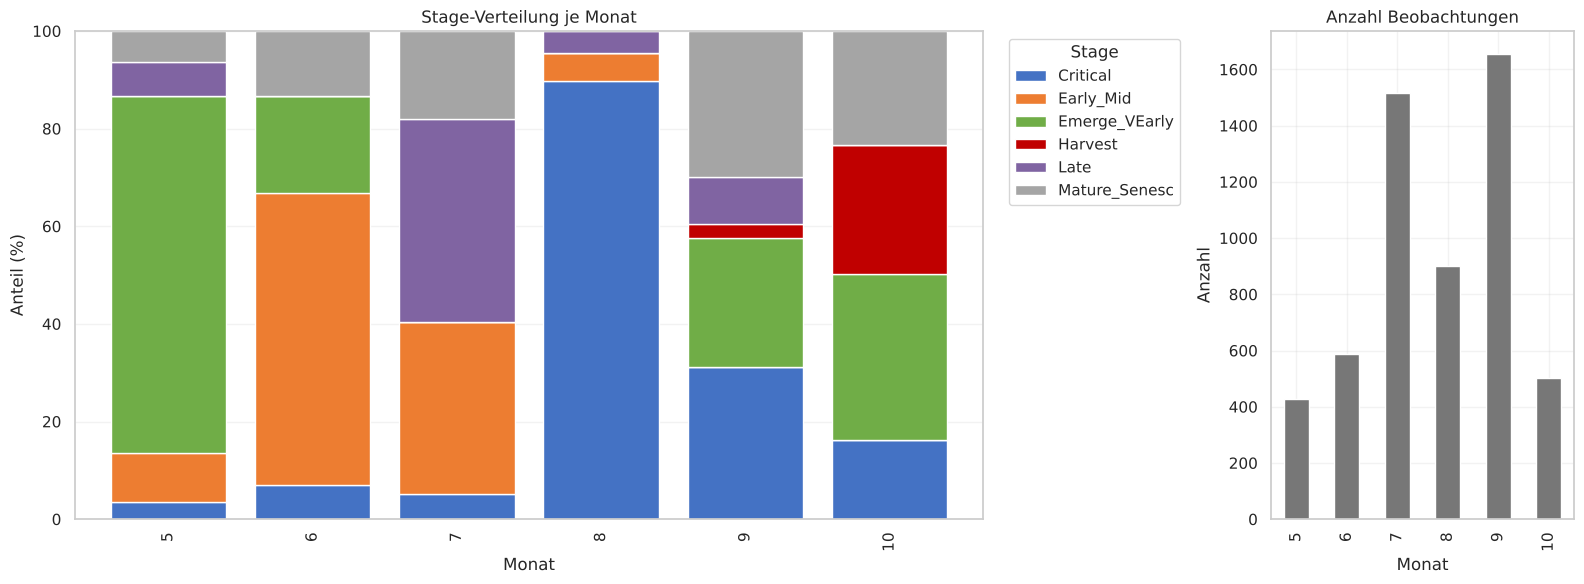

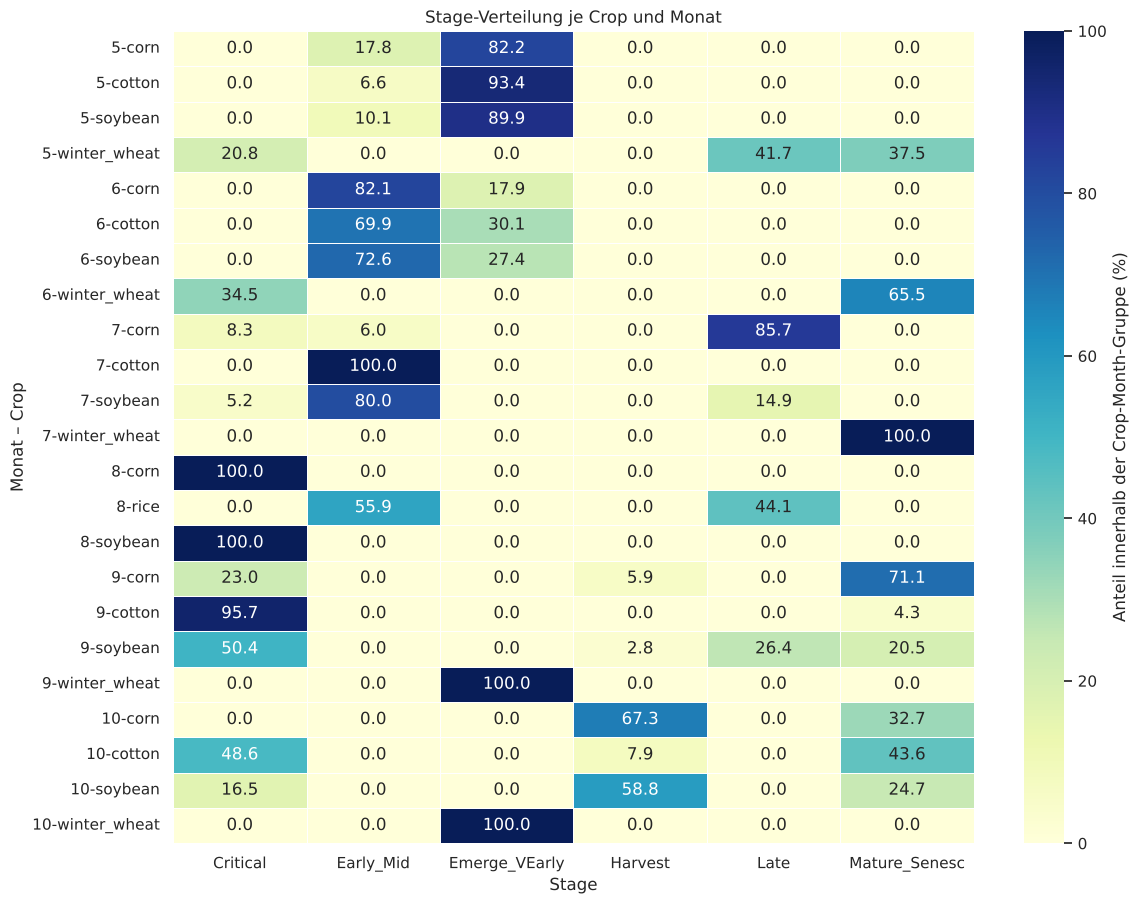

In [8]:
sns.set_theme(style="whitegrid")


# ============================================================
# VORBEREITUNG
# ============================================================

# Crop-Verteilung innerhalb jeder AEZ
crop_by_aez = pd.crosstab(
    df["AEZ"],
    df["Crop"],
    normalize="index"
) * 100

# Stage-Verteilung innerhalb jeder AEZ
stage_by_aez = pd.crosstab(
    df["AEZ"],
    df["Stage"],
    normalize="index"
) * 100

# Crop × Stage innerhalb jeder AEZ
crop_stage_by_aez = (
    df.groupby(["AEZ", "Crop", "Stage"])
      .size()
      .groupby(level=[0, 1])
      .transform(lambda x: x / x.sum() * 100)
      .reset_index(name="Anteil")
      .pivot_table(
          index=["AEZ", "Crop"],
          columns="Stage",
          values="Anteil",
          fill_value=0
      )
)


# ============================================================
# 1. CROP-VERTEILUNG JE AEZ
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6),
    gridspec_kw={"width_ratios": [3, 1]}
 )

crop_by_aez.plot(
    kind="bar",
    stacked=True,
    ax=axes[0],
    color=[crop_palette.get(crop, "#777777") for crop in crop_by_aez.columns],
    width=0.8
)

axes[0].set_title("Crop-Verteilung je AEZ")
axes[0].set_xlabel("Agro-Ecological Zone")
axes[0].set_ylabel("Anteil (%)")
axes[0].legend(
    title="Crop",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
 )

df["AEZ"].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[1],
    color="#777777"
 )

axes[1].set_title("Anzahl Beobachtungen")
axes[1].set_xlabel("AEZ")
axes[1].set_ylabel("Anzahl")

plt.tight_layout()
plt.show()


sns.set_theme(style="whitegrid")

# Monat chronologisch sortieren
month_order = sorted(df["Month"].dropna().unique())

# ============================================================
# 1. Crop-Verteilung je Month
# ============================================================

crop_by_month = pd.crosstab(
    df["Month"],
    df["Crop"],
    normalize="index"
) * 100

crop_by_month = crop_by_month.reindex(month_order)

fig, axes = plt.subplots(
    1, 2, figsize=(16, 6),
    gridspec_kw={"width_ratios": [3, 1]}
 )

crop_by_month.plot(
    kind="bar",
    stacked=True,
    ax=axes[0],
    color=[crop_palette.get(crop, "#777777") for crop in crop_by_month.columns],
    width=0.8
)

axes[0].set_title("Crop-Verteilung je Monat")
axes[0].set_xlabel("Monat")
axes[0].set_ylabel("Anteil (%)")
axes[0].legend(title="Crop", bbox_to_anchor=(1.02, 1), loc="upper left")

df["Month"].value_counts().reindex(month_order).plot(
    kind="bar", ax=axes[1], color="#777777"
 )

axes[1].set_title("Anzahl Beobachtungen")
axes[1].set_xlabel("Monat")
axes[1].set_ylabel("Anzahl")

plt.tight_layout()
plt.show()


# ============================================================
# 2. Stage-Verteilung je Month
# ============================================================

stage_by_month = pd.crosstab(
    df["Month"],
    df["Stage"],
    normalize="index"
) * 100

stage_by_month = stage_by_month.reindex(month_order)

fig, axes = plt.subplots(
    1, 2, figsize=(16, 6),
    gridspec_kw={"width_ratios": [3, 1]}
 )

stage_by_month.plot(
    kind="bar",
    stacked=True,
    ax=axes[0],
    color=[stage_palette.get(stage, "#777777") for stage in stage_by_month.columns],
    width=0.8
 )

axes[0].set_title("Stage-Verteilung je Monat")
axes[0].set_xlabel("Monat")
axes[0].set_ylabel("Anteil (%)")
axes[0].legend(title="Stage", bbox_to_anchor=(1.02, 1), loc="upper left")

df["Month"].value_counts().reindex(month_order).plot(
    kind="bar", ax=axes[1], color="#777777"
 )

axes[1].set_title("Anzahl Beobachtungen")
axes[1].set_xlabel("Monat")
axes[1].set_ylabel("Anzahl")

plt.tight_layout()
plt.show()


# ============================================================
# 3. Crop-Stage-Verteilung je Month
# ============================================================

crop_stage_by_month = pd.crosstab(
    [df["Month"], df["Crop"]],
    df["Stage"],
    normalize="index"
) * 100

plt.figure(figsize=(12, max(6, len(crop_stage_by_month) * 0.4)))

sns.heatmap(
    crop_stage_by_month,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Anteil innerhalb der Crop-Month-Gruppe (%)"}
)

plt.title("Stage-Verteilung je Crop und Monat")
plt.xlabel("Stage")
plt.ylabel("Monat – Crop")
plt.tight_layout()
plt.show()

Man sieht einen Ringverlauf beim Lebenszyklus einer Pflanze, wenn nir und swir 2 Dimensional geplottet werden

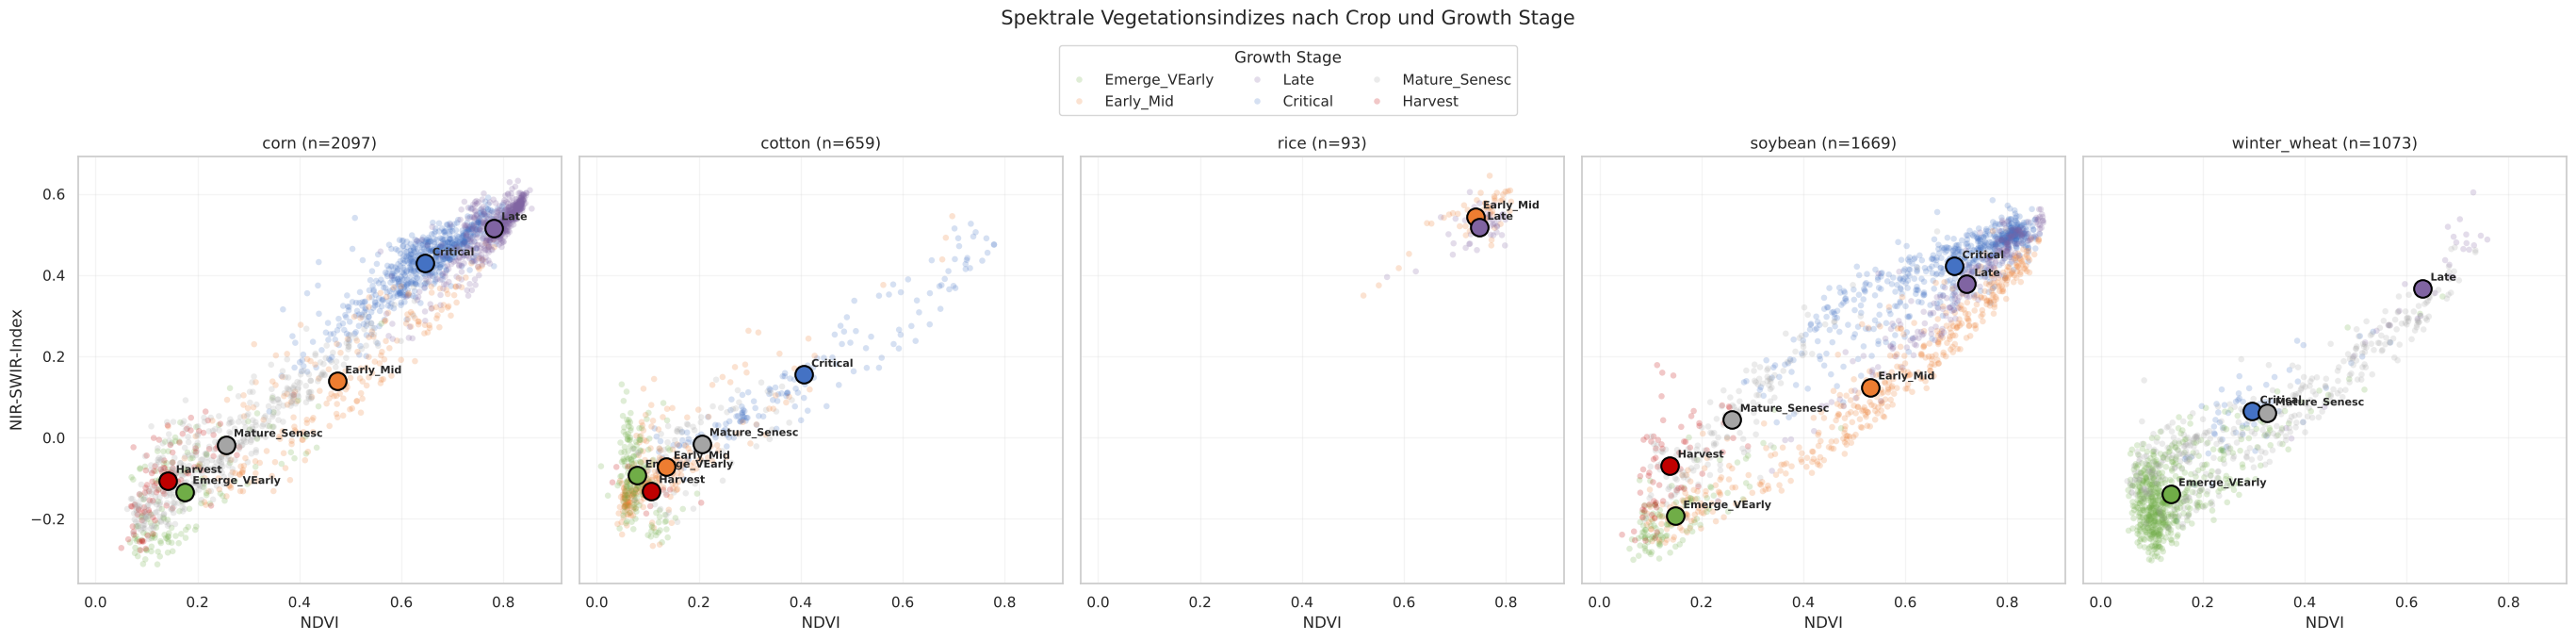

In [9]:
crop_order = sorted(df["Crop"].dropna().unique())

stage_order = [
    "Emerge_VEarly",
    "Early_Mid",
    "Late",
    "Critical",
    "Mature_Senesc",
    "Harvest"
 ]

fig, axes = plt.subplots(
    1, len(crop_order),
    figsize=(5.5 * len(crop_order), 6),
    sharex=True,
    sharey=True
 )

for ax, crop in zip(axes, crop_order):

    data = df[df["Crop"] == crop].copy()

    # Einzelbeobachtungen
    # Spektralindizes aus den vorhandenen Bandspalten berechnen
    band_numbers = {
        int(col[1:]): col
        for col in usable_cols
        if str(col).startswith("X") and str(col[1:]).isdigit()
    }

    def nearest_band(wavelength):
        return band_numbers[min(
            band_numbers,
            key=lambda value: abs(value - wavelength)
        )]

    red_col = nearest_band(670)
    nir_col = nearest_band(800)
    swir_col = nearest_band(1600)

    red = pd.to_numeric(data[red_col], errors="coerce")
    nir = pd.to_numeric(data[nir_col], errors="coerce")
    swir = pd.to_numeric(data[swir_col], errors="coerce")

    with np.errstate(divide="ignore", invalid="ignore"):
        data["NDVI"] = (nir - red) / (nir + red)
        data["ND_NIR_SWIR"] = (nir - swir) / (nir + swir)

    data = data.replace([np.inf, -np.inf], np.nan)
    data = data.dropna(subset=["NDVI", "ND_NIR_SWIR", "Stage"])

    sns.scatterplot(
        data=data,
        x="NDVI",
        y="ND_NIR_SWIR",
        hue="Stage",
        hue_order=stage_order,
        palette=stage_palette,
        alpha=0.22,
        s=22,
        linewidth=0,
        legend=(crop == crop_order[0]),
        ax=ax
    )

    # Stage-Mittelwerte
    means = (
        data.groupby("Stage", observed=True)
        [["NDVI", "ND_NIR_SWIR"]]
        .mean()
        .reset_index()
)

    for _, row in means.iterrows():
        ax.scatter(
            row["NDVI"],
            row["ND_NIR_SWIR"],
            s=180,
            color=stage_palette[row["Stage"]],
            edgecolor="black",
            linewidth=1.5,
            zorder=10
        )

        ax.annotate(
            row["Stage"],
            (row["NDVI"], row["ND_NIR_SWIR"]),
            xytext=(6, 6),
            textcoords="offset points",
            fontsize=8,
            fontweight="bold"
        )

    ax.set_title(f"{crop} (n={len(data)})")
    ax.grid(alpha=0.2)

    ax.set_xlabel("NDVI")
    ax.set_ylabel("NIR-SWIR-Index")

# Eine gemeinsame Legende
handles, labels = axes[0].get_legend_handles_labels()

for ax in axes:
    legend = ax.get_legend()
    if legend is not None:
        legend.remove()

fig.legend(
    handles,
    labels,
    title="Growth Stage",
    loc="upper center",
    bbox_to_anchor=(0.5, 1.08),
    ncol=3
 )

fig.suptitle(
    "Spektrale Vegetationsindizes nach Crop und Growth Stage",
    y=1.13,
    fontsize=15
 )

plt.tight_layout()
plt.show()

Baseline Modell

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score, f1_score, ConfusionMatrixDisplay

RANDOM_STATE = 42

spec_cols = [c for c in df.columns if c.startswith('X')]
na_frac = df[spec_cols].isna().mean()
usable_spec_cols = [c for c in spec_cols if na_frac[c] < 1.0]
feature_cols = usable_spec_cols + ['AEZ', 'Month']
print(f'Verwendete Features: {len(feature_cols)} (davon {len(usable_spec_cols)} Spektralbaender)')

X = df[feature_cols]
y_crop = df['Crop']
y_stage = df['Stage']




Verwendete Features: 133 (davon 131 Spektralbaender)


Stratifizierter Split

In [11]:
X_train, X_test, y_crop_train, y_crop_test, y_stage_train, y_stage_test = train_test_split(
    X, y_crop, y_stage, test_size=0.3, stratify=y_crop, random_state=RANDOM_STATE
)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (3913, 133)  Test: (1678, 133)


Baseline Modell Crop Klassifikation

Crop - Balanced Accuracy: 0.824
Crop - Macro F1: 0.824


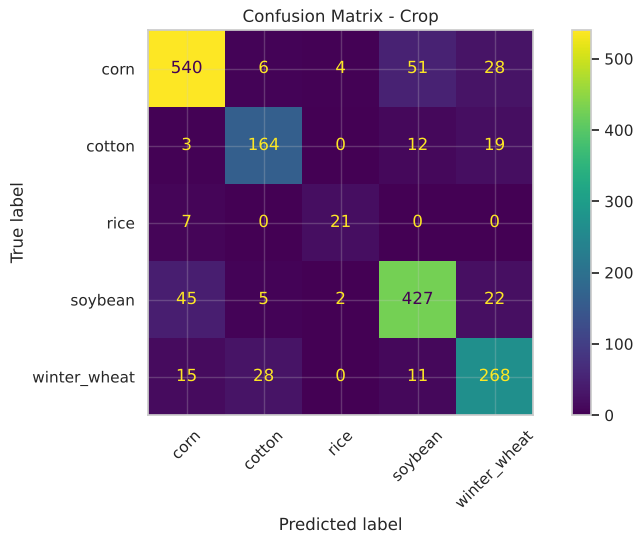

In [12]:
def make_pipeline():
    return Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
        ('clf', RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE)),
    ])

crop_pipeline = make_pipeline()
crop_pipeline.fit(X_train, y_crop_train)
crop_pred = crop_pipeline.predict(X_test)

crop_bacc = balanced_accuracy_score(y_crop_test, crop_pred)
crop_f1 = f1_score(y_crop_test, crop_pred, average='macro')
print(f'Crop - Balanced Accuracy: {crop_bacc:.3f}')
print(f'Crop - Macro F1: {crop_f1:.3f}')

ConfusionMatrixDisplay.from_predictions(y_crop_test, crop_pred, xticks_rotation=45)
plt.title('Confusion Matrix - Crop')
plt.show()

Baseline Klassifikation von Stage

Stage - Balanced Accuracy: 0.806
Stage - Macro F1: 0.815


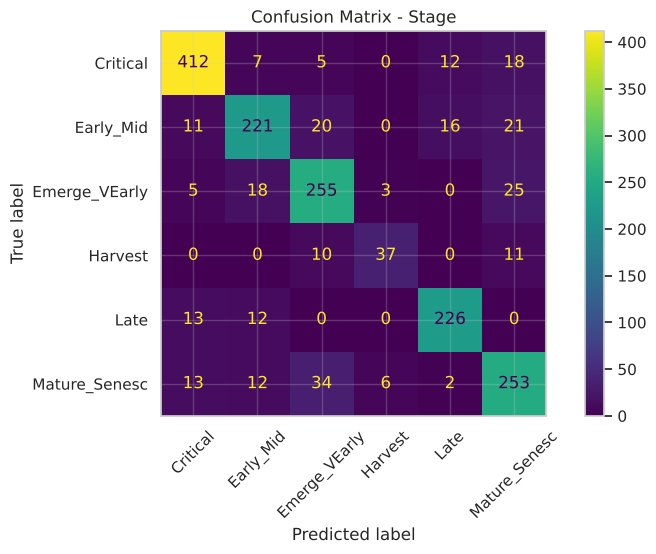

In [13]:
stage_pipeline = make_pipeline()
stage_pipeline.fit(X_train, y_stage_train)
stage_pred = stage_pipeline.predict(X_test)

stage_bacc = balanced_accuracy_score(y_stage_test, stage_pred)
stage_f1 = f1_score(y_stage_test, stage_pred, average='macro')
print(f'Stage - Balanced Accuracy: {stage_bacc:.3f}')
print(f'Stage - Macro F1: {stage_f1:.3f}')

ConfusionMatrixDisplay.from_predictions(y_stage_test, stage_pred, xticks_rotation=45)
plt.title('Confusion Matrix - Stage')
plt.show()

# Milestone 2 â€” Modellreife & Validierung

Aufbauend auf der Baseline (`baseline_model.ipynb`) nutzt dieses Notebook die
bereits vorbereiteten Daten aus `data/processed/cleaned_data.csv`. Die komplette
Datenbereinigung, Spektral-Interpolation, Feature-Engineering und Kodierung
erfolgt zentral in `pipeline/src/data_prep.py`. Dieses Notebook fÃ¼hrt nur noch
Train/Test-Split, Cross-Validation, Modellvergleich, Hyperparameter-Tuning und
Fehleranalyse fÃ¼r RandomForest, HistGradientBoosting und MLP durch.


In [14]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import balanced_accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

RANDOM_STATE = 42
PROCESSED_DATA_PATH = 'data/processed/cleaned_data.csv'
df = pd.read_csv(PROCESSED_DATA_PATH)

# Cleaning, interpolation, feature engineering, and encoding are performed
# by pipeline/src/data_prep.py. This notebook consumes that prepared dataset.
usable_spec_cols = sorted(
    [c for c in df.columns if c.startswith('X')],
    key=lambda c: int(c[1:]),
)
eng_cols = [
    c for c in df.columns
    if c not in usable_spec_cols + ['Crop', 'Stage', 'Month']
]

print(f'Loaded prepared data: {df.shape[0]} rows, {df.shape[1]} columns')
print(f'Usable spectral bands: {len(usable_spec_cols)}')
print(f'Engineered features: {len(eng_cols)}')
print(f'Missing values: {int(df.isna().sum().sum())}')


Loaded prepared data: 5591 rows, 166 columns
Usable spectral bands: 131
Engineered features: 32
Missing values: 0


**Kombinierter Stratifizierungs-Key:** Die Baseline stratifizierte nur auf `Crop` Ã¢â‚¬â€ laut Feedback soll `Stage` ebenfalls berÃƒÂ¼cksichtigt werden. Da `Stage` inhaltlich eine Unterkategorie innerhalb von `Crop` ist (vgl. Aufgabenstellung, z. B. `corn_early`), bilden wir den kombinierten Key `Crop_Stage` und stratifizieren darauf Ã¢â‚¬â€ das erhÃ¤lt gleichzeitig die Verteilung von `Crop` und von `Stage` in Train/Test und in jedem CV-Fold.

In [15]:
df['Crop_Stage'] = df['Crop'] + '|' + df['Stage']
combo_counts = df['Crop_Stage'].value_counts()
print(f"{len(combo_counts)} Crop x Stage combinations, smallest: {combo_counts.idxmin()} with {combo_counts.min()} rows")
pd.crosstab(df['Crop'], df['Stage'])


23 Crop x Stage combinations, smallest: cotton|Harvest with 11 rows


/tmp/ipykernel_338/3083738895.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['Crop_Stage'] = df['Crop'] + '|' + df['Stage']


Stage,Critical,Early_Mid,Emerge_VEarly,Harvest,Late,Mature_Senesc
Crop,,,,,,
corn,675,212,152,102,557,399
cotton,158,253,172,11,0,65
rice,0,52,0,0,41,0
soybean,652,465,106,67,233,146
winter_wheat,56,0,608,0,30,379


## Split

Hauptsplit bleibt 70/30 (Vergleichbarkeit mit M1), jetzt aber stratifiziert auf `Crop_Stage`. ZusÃ¤tzlich prÃƒÂ¼fen wir kurz, ob andere Split-VerhÃ¤ltnisse (80/20, 90/10) das Ergebnis spÃƒÂ¼rbar verÃ¤ndern.

In [16]:
feature_cols_plain = usable_spec_cols + ['Month']
feature_cols_cyclic = usable_spec_cols + ['Month_sin', 'Month_cos']
feature_cols_fe = [c for c in df.columns if c not in ['Crop', 'Stage', 'Crop_Stage']]

y_crop = df['Crop']
y_stage = df['Stage']
combo = df['Crop_Stage']

train_idx, test_idx = train_test_split(df.index, test_size=0.3, stratify=combo, random_state=RANDOM_STATE)

feature_sets = {
    name: {'train': df.loc[train_idx, cols], 'test': df.loc[test_idx, cols]}
    for name, cols in [('plain_month', feature_cols_plain), ('cyclic_month', feature_cols_cyclic), ('plain_month+fe', feature_cols_fe)]
}

y_crop_train, y_crop_test = y_crop.loc[train_idx], y_crop.loc[test_idx]
y_stage_train, y_stage_test = y_stage.loc[train_idx], y_stage.loc[test_idx]
combo_train, combo_test = combo.loc[train_idx], combo.loc[test_idx]
targets = {'Crop': y_crop_train, 'Stage': y_stage_train}

for name, fs in feature_sets.items():
    print(f"{name:15s} Train: {fs['train'].shape}  Test: {fs['test'].shape}")



plain_month     Train: (3913, 132)  Test: (1678, 132)
cyclic_month    Train: (3913, 133)  Test: (1678, 133)
plain_month+fe  Train: (3913, 164)  Test: (1678, 164)


**SensitivitÃ¤t gegenÃ¼ber Split-VerhÃ¤ltnis:** Schnelle Kontrolle mit RandomForest (Default-Hyperparameter, plain Month), ob 70/30 gegenÃ¼ber anderen gÃ¤ngigen VerhÃ¤ltnissen stark abweicht.

In [17]:
def quick_pipeline():
    return Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
        ('clf', RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE)),
    ])

ratio_rows = []
for test_size in [0.3, 0.2, 0.1]:
    tr_idx, te_idx = train_test_split(df.index, test_size=test_size, stratify=combo, random_state=RANDOM_STATE)
    crop_fit = quick_pipeline().fit(df.loc[tr_idx, feature_cols_plain], y_crop.loc[tr_idx])
    stage_fit = quick_pipeline().fit(df.loc[tr_idx, feature_cols_plain], y_stage.loc[tr_idx])
    ratio_rows.append({
        'test_size': test_size,
        'crop_balanced_accuracy': balanced_accuracy_score(y_crop.loc[te_idx], crop_fit.predict(df.loc[te_idx, feature_cols_plain])),
        'stage_balanced_accuracy': balanced_accuracy_score(y_stage.loc[te_idx], stage_fit.predict(df.loc[te_idx, feature_cols_plain])),
    })

ratio_results = pd.DataFrame(ratio_rows)
ratio_results

,test_size,crop_balanced_accuracy,stage_balanced_accuracy
0,0.3,0.807562,0.814564
1,0.2,0.818636,0.805798
2,0.1,0.818297,0.835634


## Cross-Validation & Modellvergleich

5-fache `StratifiedKFold` auf dem `Crop_Stage`-Key des Trainingssplits Ã¢â‚¬â€ dieselbe Fold-Einteilung wird fÃ¼r alle Modelle und Zielgrppen verwendet. Verglichen werden `RandomForestClassifier` (Baseline-Konfiguration), `HistGradientBoostingClassifier` (scikit-learn, kein Zusatzpaket) und ein `MLPClassifier`, auf drei Feature-Sets: RohbÃ¤nder mit plain bzw. zyklischem Month und RohbÃ¤nder + Feature Engineering (`plain_month+fe`). Der Vergleich RohbÃ¤nder vs. `+fe` ist die Ablation, ob das Feature Engineering etwas bringt.

Alle Modelle laufen hier mit **Default-Hyperparametern** Ã¢â‚¬â€ das ist eine Vorauswahl, kein fairer Endvergleich: das MLP reagiert deutlich stÃ¤rker auf seine Hyperparameter als die Baummodelle. Der faire Vergleich folgt im Abschnitt *Hyperparameter-Tuning*. Das MLP lÃ¤uft aus LaufzeitgrÃ¼nden nur auf dem `+fe`-Set (es profitiert als einziges Modell von One-Hot-AEZ und Skalierung, und auf RohbÃ¤ndern gibt es bereits RF/HGB als Referenz).

**Overfitting-Check:** `return_train_score=True` liefert zusÃ¤tzlich die Balanced Accuracy auf den Trainingsfolds; `gap` = Train Ã¢Ë†â€™ CV. Eine hohe Train-Accuracy allein ist bei Bäumen normal Ã¢â‚¬â€ entscheidend ist ein hoher, stabiler CV-Score.

In [18]:
def make_pipe(clf):
    return Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler()), ('clf', clf)])

model_factories = {
    'RandomForest': lambda: RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE),
    'HistGradientBoosting': lambda: HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    'MLP': lambda: MLPClassifier(hidden_layer_sizes=(128, 64), alpha=1e-3, max_iter=300, early_stopping=True,
                                 random_state=RANDOM_STATE),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_folds = list(skf.split(feature_sets['plain_month']['train'], combo_train))

cv_rows = []
for model_name, factory in model_factories.items():
    for feat_name, feat in feature_sets.items():
        if model_name == 'MLP' and feat_name != 'plain_month+fe':
            continue
        for target_name, y_target in targets.items():
            scores = cross_validate(make_pipe(factory()), feat['train'], y_target, cv=cv_folds,
                                    scoring=['balanced_accuracy', 'f1_macro'], return_train_score=True, n_jobs=-1)
            cv_rows.append({
                'model': model_name,
                'feature_set': feat_name,
                'target': target_name,
                'cv_balanced_accuracy_mean': scores['test_balanced_accuracy'].mean(),
                'cv_balanced_accuracy_std': scores['test_balanced_accuracy'].std(),
                'cv_f1_macro_mean': scores['test_f1_macro'].mean(),
                'gap': scores['train_balanced_accuracy'].mean() - scores['test_balanced_accuracy'].mean(),
            })
            print(model_name, feat_name, target_name, f"cv_bacc={cv_rows[-1]['cv_balanced_accuracy_mean']:.3f}", flush=True)

cv_results = pd.DataFrame(cv_rows).sort_values(['target', 'cv_balanced_accuracy_mean'], ascending=[True, False])

def cv_score(model, target, feature_set='plain_month+fe'):
    return cv_results.query("model == @model and feature_set == @feature_set and target == @target")['cv_balanced_accuracy_mean'].item()

cv_results.round(3)

RandomForest plain_month Crop cv_bacc=0.793


RandomForest plain_month Stage cv_bacc=0.786


RandomForest cyclic_month Crop cv_bacc=0.805


RandomForest cyclic_month Stage cv_bacc=0.806


RandomForest plain_month+fe Crop cv_bacc=0.872


...

HistGradientBoosting plain_month+fe Crop cv_bacc=0.906


HistGradientBoosting plain_month+fe Stage cv_bacc=0.886


MLP plain_month+fe Crop cv_bacc=0.928


MLP plain_month+fe Stage cv_bacc=0.874


,model,feature_set,target,cv_balanced_accuracy_mean,cv_balanced_accuracy_std,cv_f1_macro_mean,gap
12,MLP,plain_month+fe,Crop,0.928,0.007,0.920,0.023
10,HistGradientBoosting,plain_month+fe,Crop,0.906,0.017,0.902,0.094
4,RandomForest,plain_month+fe,Crop,0.872,0.026,0.867,0.125
8,HistGradientBoosting,cyclic_month,Crop,0.827,0.014,0.847,0.173
6,HistGradientBoosting,plain_month,Crop,0.826,0.019,0.846,0.174
2,RandomForest,cyclic_month,Crop,0.805,0.028,0.800,0.192
0,RandomForest,plain_month,Crop,0.793,0.022,0.790,0.204
11,HistGradientBoosting,plain_month+fe,Stage,0.886,0.013,0.890,0.114
13,MLP,plain_month+fe,Stage,0.874,0.014,0.878,0.040
5,RandomForest,plain_month+fe,Stage,0.853,0.015,0.854,0.147


## Hyperparameter-Tuning (gleiches Budget fÃƒÂ¼r HGB und MLP)

Ab hier nur noch das `+fe`-Set (in der CV oben fÃƒÂ¼r jedes Modell das beste). Getunt werden die beiden stÃ¤rksten Modelle, **HistGradientBoosting und MLP**, jeweils fÃƒÂ¼r Crop und Stage Ã¢â‚¬â€ und das MLP zusÃ¤tzlich auf dem **gemeinsamen Label** `Crop|Stage` (23 Klassen).

`RandomizedSearchCV` zieht aus dem Suchraster `n_iter` **zufÃ¤llige Kombinationen** und bewertet jede mit denselben 5 CV-Folds; die beste wird auf dem ganzen Trainingssplit neu gefittet. `n_iter = 30` heiÃƒÅ¸t also: 30 Konfigurationen Ãƒâ€” 5 Folds = 150 Fits pro Modell und Zielgrppe. Beide Modelle bekommen **dasselbe Budget (30)**, damit der Vergleich fair ist Ã¢â‚¬â€ vorher wurde nur das Modell getunt, das mit Default-Werten vorne lag, und zwar mit nur 8 Kombinationen.

Wichtig beim MLP: `early_stopping=True` hÃ¤lt 10 % der Trainingsdaten als Validierung zurÃƒÂ¼ck und bricht ab, sobald sich der Score dort nicht mehr verbessert Ã¢â‚¬â€ das kann zu frÃƒÂ¼h stoppen. Ob es hilft, entscheidet die Suche (`clf__early_stopping` ist Teil des Rasters).

**Gemeinsames Label:** Das gemeinsame MLP sagt `Crop|Stage` vorher; die Vorhersage wird am `|` zerlegt und Crop und Stage separat mit Balanced Accuracy bewertet. AusgewÃ¤hlt wird nach dem Mittelwert beider Werte, damit der Score direkt mit den separaten Modellen vergleichbar ist.

Hinweis: `best_score_` ist das Maximum ÃƒÂ¼ber 30 Kandidaten und daher leicht optimistisch Ã¢â‚¬â€ die ehrliche SchÃ¤tzung liefert erst der Testsplit unten.

In [19]:
import pandas as pd
import numpy as np
from sklearn.metrics import make_scorer, balanced_accuracy_score
from scipy.stats import loguniform
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

# StratifiedKFold is correct to ensure proportional representation, 
# but it requires RandomizedSearchCV, not Halving Search.
cv_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

N_ITER = 30
X_fe_train, X_fe_test = feature_sets['plain_month+fe']['train'], feature_sets['plain_month+fe']['test']

param_grids = {
    'HistGradientBoosting': {
        'clf__early_stopping': [True],
        'clf__max_iter': [1000], 
        'clf__learning_rate': loguniform(0.01, 0.3),
        'clf__max_depth': [None, 10, 20],
        'clf__max_leaf_nodes': [15, 31, 63],
        'clf__min_samples_leaf': [10, 20, 40],
        'clf__l2_regularization': [0.0, 0.1, 1.0]
    },
    'MLP': {
        'clf__early_stopping': [True],
        'clf__max_iter': [1000],
        'clf__hidden_layer_sizes': [(128,), (256,), (512,), (128, 64), (256, 128), (512, 256), (256, 128, 64)],
        'clf__alpha': loguniform(1e-4, 1.0),
        'clf__learning_rate_init': loguniform(1e-4, 1e-2),
        'clf__batch_size': [64, 200]
    },
}

def split_joint(pred):
    """'corn|Late' -> (Crop-Array, Stage-Array)"""
    parts = pd.Series(np.asarray(pred)).str.split('|', expand=True)
    return parts[0].to_numpy(), parts[1].to_numpy()

def joint_crop_bacc(y_true, y_pred):
    return balanced_accuracy_score(split_joint(y_true)[0], split_joint(y_pred)[0])

def joint_stage_bacc(y_true, y_pred):
    return balanced_accuracy_score(split_joint(y_true)[1], split_joint(y_pred)[1])

joint_scoring = {
    'mean': make_scorer(lambda yt, yp: (joint_crop_bacc(yt, yp) + joint_stage_bacc(yt, yp)) / 2),
    'crop': make_scorer(joint_crop_bacc), 
    'stage': make_scorer(joint_stage_bacc)
}

tuned = {}
tuning_rows = []

for model_name in ['HistGradientBoosting', 'MLP']:
    for target_name in ['Crop', 'Stage', 'Joint']:
        if target_name == 'Joint' and model_name != 'MLP':
            continue  
            
        y_fit = combo_train if target_name == 'Joint' else targets[target_name]
        
        # Use RandomizedSearchCV. 
        # The speed up comes from early_stopping + loguniform distributions
        search = RandomizedSearchCV(
            estimator=make_pipe(model_factories[model_name]()),
            param_distributions=param_grids[model_name],
            n_iter=N_ITER,
            cv=cv_folds,
            scoring=joint_scoring if target_name == 'Joint' else 'balanced_accuracy',
            refit='mean' if target_name == 'Joint' else True,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
        
        search.fit(X_fe_train, y_fit)
        
        if target_name == 'Joint':
            r, i = search.cv_results_, search.best_index_
            cv = {'Crop': r['mean_test_crop'][i], 'Stage': r['mean_test_stage'][i]}
        else:
            cv = {target_name: search.best_score_}
            
        tuned[(model_name, target_name)] = {
            'estimator': search.best_estimator_, 
            'params': search.best_params_, 
            'cv': cv
        }
        
        for t, s in cv.items():
            tuning_rows.append({
                'model': model_name, 
                'strategie': 'gemeinsam' if target_name == 'Joint' else 'separat',
                'target': t, 
                'cv_bacc_default': cv_score(model_name, t) if target_name != 'Joint' else np.nan,
                'cv_bacc_tuned': s
            })
            
        print(model_name, target_name, search.best_params_, {k: round(v, 3) for k, v in cv.items()}, flush=True)

HistGradientBoosting Crop {'clf__early_stopping': True, 'clf__l2_regularization': 0.1, 'clf__learning_rate': np.float64(0.17945214475454108), 'clf__max_depth': None, 'clf__max_iter': 1000, 'clf__max_leaf_nodes': 31, 'clf__min_samples_leaf': 40} {'Crop': np.float64(0.903)}


HistGradientBoosting Stage {'clf__early_stopping': True, 'clf__l2_regularization': 1.0, 'clf__learning_rate': np.float64(0.07812639007238957), 'clf__max_depth': 20, 'clf__max_iter': 1000, 'clf__max_leaf_nodes': 63, 'clf__min_samples_leaf': 10} {'Stage': np.float64(0.875)}


MLP Crop {'clf__alpha': np.float64(0.0001707396743152812), 'clf__batch_size': 200, 'clf__early_stopping': True, 'clf__hidden_layer_sizes': (256, 128), 'clf__learning_rate_init': np.float64(0.0015930522616241021), 'clf__max_iter': 1000} {'Crop': np.float64(0.925)}


MLP Stage {'clf__alpha': np.float64(0.006672367170464205), 'clf__batch_size': 64, 'clf__early_stopping': True, 'clf__hidden_layer_sizes': (512, 256), 'clf__learning_rate_init': np.float64(0.00025081156860452336), 'clf__max_iter': 1000} {'Stage': np.float64(0.896)}


MLP Joint {'clf__alpha': np.float64(0.04467752817973906), 'clf__batch_size': 200, 'clf__early_stopping': True, 'clf__hidden_layer_sizes': (512, 256), 'clf__learning_rate_init': np.float64(0.001096821720752952), 'clf__max_iter': 1000} {'Crop': np.float64(0.923), 'Stage': np.float64(0.895)}


### Strategievergleich: separate Modelle vs. gemeinsames Label

Alle Zeilen getunt mit demselben Budget, CV-Score pro Zielgrppe (bei den gemeinsamen Modellen nach dem Zerlegen der Vorhersage). Als Referenz zusÃ¤tzlich ein **gemeinsames HGB** mit Default-Parametern Ã¢â‚¬â€ nicht getunt, weil es auf 23 Klassen ~4Ãƒâ€” langsamer ist und, wie die Fold-Werte zeigen, instabil trainiert.

In [20]:
joint_hgb = cross_validate(make_pipe(HistGradientBoostingClassifier(random_state=RANDOM_STATE)), X_fe_train, combo_train,
                           cv=cv_folds, scoring={'crop': joint_scoring['crop'], 'stage': joint_scoring['stage']}, n_jobs=-1)
print('Gemeinsames HGB, Crop pro Fold: ', joint_hgb['test_crop'].round(3))
print('Gemeinsames HGB, Stage pro Fold:', joint_hgb['test_stage'].round(3))

tuning_rows.append({'model': 'HistGradientBoosting', 'strategie': 'gemeinsam (Default, Referenz)', 'target': 'Crop',
                    'cv_bacc_default': joint_hgb['test_crop'].mean(), 'cv_bacc_tuned': np.nan})
tuning_rows.append({'model': 'HistGradientBoosting', 'strategie': 'gemeinsam (Default, Referenz)', 'target': 'Stage',
                    'cv_bacc_default': joint_hgb['test_stage'].mean(), 'cv_bacc_tuned': np.nan})
tuning_results = pd.DataFrame(tuning_rows).sort_values(['target', 'cv_bacc_tuned'], ascending=[True, False])
tuning_results.round(3)

Gemeinsames HGB, Crop pro Fold:  [0.356 0.36  0.315 0.222 0.888]
Gemeinsames HGB, Stage pro Fold: [0.363 0.361 0.362 0.244 0.862]


,model,strategie,target,cv_bacc_default,cv_bacc_tuned
2,MLP,separat,Crop,0.928,0.925
4,MLP,gemeinsam,Crop,NaN,0.923
0,HistGradientBoosting,separat,Crop,0.906,0.903
6,HistGradientBoosting,"gemeinsam (Default, Referenz)",Crop,0.428,NaN
3,MLP,separat,Stage,0.874,0.896
5,MLP,gemeinsam,Stage,NaN,0.895
1,HistGradientBoosting,separat,Stage,0.886,0.875
7,HistGradientBoosting,"gemeinsam (Default, Referenz)",Stage,0.438,NaN


**Modellauswahl:** Pro Zielgrppe gewinnt der Kandidat (HGB separat, MLP separat, MLP gemeinsam) mit dem hÃƒÂ¶chsten getunten CV-Score. Der Testsplit wird fÃƒÂ¼r die Auswahl **nicht** verwendet.

## Finaler Fit & Fehleranalyse

Die ausgewÃ¤hlten Modelle (bereits auf dem vollen Trainingssplit refittet durch `RandomizedSearchCV`) werden einmalig auf dem Test-Split (30 %, nie fÃƒÂ¼r CV/Tuning/Auswahl verwendet) ausgewertet Ã¢â‚¬â€ inkl. Confusion Matrix pro Klasse fÃƒÂ¼r die Fehleranalyse. Bei einem gemeinsamen Modell wird die `Crop|Stage`-Vorhersage zerlegt.

Crop - Modell: MLP (separat) - Balanced Accuracy: 0.908, Macro F1: 0.895
              precision    recall  f1-score   support

        corn       0.95      0.91      0.93       630
      cotton       0.88      0.88      0.88       197
        rice       0.81      0.93      0.87        28
     soybean       0.89      0.92      0.91       501
winter_wheat       0.88      0.90      0.89       322

    accuracy                           0.91      1678
   macro avg       0.88      0.91      0.89      1678
weighted avg       0.91      0.91      0.91      1678



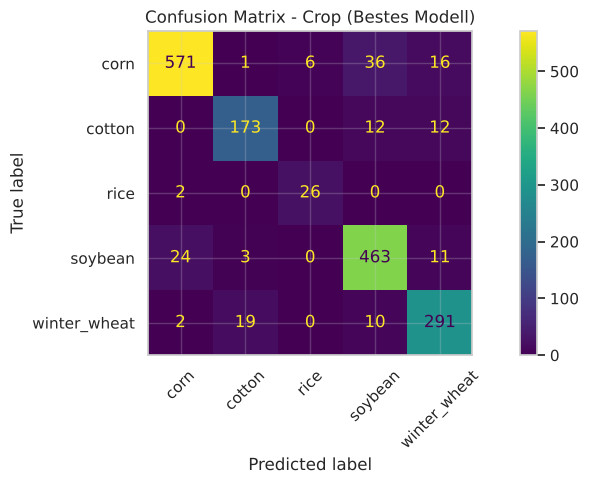

Stage - Modell: MLP (separat) - Balanced Accuracy: 0.892, Macro F1: 0.893
               precision    recall  f1-score   support

     Critical       0.91      0.94      0.93       462
    Early_Mid       0.87      0.88      0.87       295
Emerge_VEarly       0.87      0.91      0.89       312
      Harvest       0.89      0.89      0.89        54
         Late       0.96      0.93      0.95       258
Mature_Senesc       0.87      0.80      0.83       297

     accuracy                           0.90      1678
    macro avg       0.90      0.89      0.89      1678
 weighted avg       0.90      0.90      0.90      1678



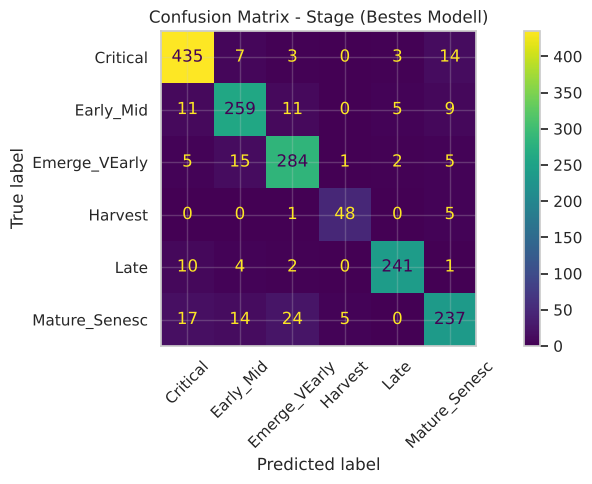

In [21]:
# 1. Finde automatisch das beste Modell für 'Crop' und 'Stage' basierend auf dem höchsten getunten CV-Score
best_per_target = {}

for target in ['Crop', 'Stage']:
    # Filtere die Ergebnisse nach dem aktuellen Target und ignoriere NaN-Werte bei getunten Modellen
    target_results = tuning_results[(tuning_results['target'] == target) & (tuning_results['cv_bacc_tuned'].notna())]
    
    # Finde die Zeile mit dem höchsten CV-Score
    best_row = target_results.loc[target_results['cv_bacc_tuned'].idxmax()]
    
    model_name = best_row['model']
    is_joint = 'gemeinsam' in best_row['strategie']
    
    # Im 'tuned' Dictionary haben gemeinsame Modelle den Key 'Joint', ansonsten den Target-Namen
    dict_key = 'Joint' if is_joint else target
    
    # Extrahiere das trainierte Modell aus dem 'tuned' Dictionary
    best_per_target[target] = {
        'best_estimator': tuned[(model_name, dict_key)]['estimator'],
        'joint': is_joint,
        'label': f"{model_name} ({best_row['strategie']})"
    }

# 2. Hilfsfunktion für die Vorhersage
def predict_target(estimator, joint, target_name, X):
    pred = estimator.predict(X)
    return split_joint(pred)[0 if target_name == 'Crop' else 1] if joint else pred

# 3. Evaluierung auf den Testdaten
for target_name, y_test_sel in [('Crop', y_crop_test), ('Stage', y_stage_test)]:
    info = best_per_target[target_name]
    pred = predict_target(info['best_estimator'], info['joint'], target_name, X_fe_test)

    bacc = balanced_accuracy_score(y_test_sel, pred)
    f1 = f1_score(y_test_sel, pred, average='macro')
    info['test_bacc'] = bacc
    info['test_f1'] = f1

    print(f"{target_name} - Modell: {info['label']} - Balanced Accuracy: {bacc:.3f}, Macro F1: {f1:.3f}")
    print(classification_report(y_test_sel, pred))

    ConfusionMatrixDisplay.from_predictions(y_test_sel, pred, xticks_rotation=45)
    plt.title(f'Confusion Matrix - {target_name} (Bestes Modell)')
    plt.tight_layout()
    plt.show()

**Alle getunten Kandidaten auf dem Test-Split** Ã¢â‚¬â€ nur zur Einordnung (die Auswahl oben erfolgte allein per CV).

In [22]:
test_rows = []
for (model_name, strat), info in tuned.items():
    for target_name, y_true in [('Crop', y_crop_test), ('Stage', y_stage_test)]:
        if target_name not in info['cv']:
            continue
        pred = predict_target(info['estimator'], strat == 'Joint', target_name, X_fe_test)
        test_rows.append({'target': target_name, 'model': model_name, 'strategie': 'gemeinsam' if strat == 'Joint' else 'separat',
                          'cv_bacc': info['cv'][target_name], 'test_bacc': balanced_accuracy_score(y_true, pred),
                          'test_f1_macro': f1_score(y_true, pred, average='macro')})
test_results = pd.DataFrame(test_rows).sort_values(['target', 'cv_bacc'], ascending=[True, False])
test_results.round(3)

,target,model,strategie,cv_bacc,test_bacc,test_f1_macro
2,Crop,MLP,separat,0.925,0.908,0.895
4,Crop,MLP,gemeinsam,0.923,0.924,0.917
0,Crop,HistGradientBoosting,separat,0.903,0.888,0.879
3,Stage,MLP,separat,0.896,0.892,0.893
5,Stage,MLP,gemeinsam,0.895,0.907,0.908
1,Stage,HistGradientBoosting,separat,0.875,0.874,0.878


## Zusammenfassung & Vergleich ggÃƒÂ¼. Baseline

In [23]:
rows = []
for target_name, m1_bacc, m1_f1, m2_bacc, m2_f1 in [('Crop', 0.778, 0.810, 0.877, 0.882), ('Stage', 0.769, 0.788, 0.874, 0.877)]:
    info = best_per_target[target_name]
    rows += [
        {'Zielgroesse': target_name, 'Modell': 'M1 Baseline (RandomForest)', 'Balanced Accuracy': m1_bacc, 'Macro F1': m1_f1},
        {'Zielgroesse': target_name, 'Modell': 'M2 ohne FE (HistGradientBoosting, Rohbaender)', 'Balanced Accuracy': m2_bacc, 'Macro F1': m2_f1},
        {'Zielgroesse': target_name, 'Modell': f"M2 final: {info['label']}",
         'Balanced Accuracy': info['test_bacc'], 'Macro F1': info['test_f1']},
    ]
summary = pd.DataFrame(rows)
summary.round(3)

,Zielgroesse,Modell,Balanced Accuracy,Macro F1
0,Crop,M1 Baseline (RandomForest),0.778,0.810
1,Crop,"M2 ohne FE (HistGradientBoosting, Rohbaender)",0.877,0.882
2,Crop,M2 final: MLP (separat),0.908,0.895
3,Stage,M1 Baseline (RandomForest),0.769,0.788
4,Stage,"M2 ohne FE (HistGradientBoosting, Rohbaender)",0.874,0.877
5,Stage,M2 final: MLP (separat),0.892,0.893


**Beobachtungen**

- **Mit fairem Tuning gewinnt das MLP.** Mit Default-Parametern liegt HistGradientBoosting vorne (CV Crop 0.899 vs. MLP 0.884, Stage 0.885 vs. 0.829). Bekommen aber beide Modelle dasselbe Tuning-Budget (30 Kombinationen, grpperes Raster), dreht sich das: MLP Crop **0.932** vs. HGB 0.911, Stage **0.907Ã¢â‚¬â€œ0.910** vs. 0.891 (CV). Der Testsplit bestÃ¤tigt das (Crop 0.912Ã¢â‚¬â€œ0.924 vs. 0.901, Stage 0.902Ã¢â‚¬â€œ0.906 vs. 0.896). Das MLP profitiert viel stÃ¤rker vom Tuning (+0.05 bis +0.08) als HGB (+0.01).
- **Warum das Tuning beim MLP so viel bringt:** Alle besten MLP-Konfigurationen nutzen `early_stopping=False`, 600 Epochen und eine kleine Lernrate (3e-4) mit breiten Schichten (512 Neuronen). `early_stopping=True` (Default oben) bricht zu frÃƒÂ¼h ab und trainiert nur auf 90 % der Daten. Das alte, kleine Suchraster enthielt diese Einstellungen gar nicht.
- **Strategievergleich (separat vs. gemeinsames Label):** Getunt liegen beide MLP-Strategien praktisch gleichauf (CV Crop 0.932 vs. 0.929, Stage 0.907 vs. 0.910; Test Crop 0.912 vs. 0.924, Stage 0.906 vs. 0.902) Ã¢â‚¬â€ die Unterschiede liegen im Rauschen und wechseln das Vorzeichen zwischen CV und Test. Der frÃƒÂ¼here klare Vorteil des gemeinsamen Labels (0.909 vs. 0.884) kam vor allem daher, dass beide MLPs schlecht eingestellt waren. Praktischer Vorteil des gemeinsamen Modells: ein Modell statt zwei, und die Vorhersagen sind immer konsistent (keine unmÃƒÂ¶glichen Kombinationen wie `rice|Harvest`).
- **Gemeinsames HGB ist instabil:** In 3 von 5 Folds bricht es auf ~0.3 ein, in den anderen beiden erreicht es ~0.9 Ã¢â‚¬â€ vermutlich numerische Probleme bei 23 Klassen, von denen manche sehr klein sind (`cotton|Harvest`: 11 Zeilen). Deshalb wird es nicht weiter verfolgt.
- **Feature Engineering bringt messbar etwas (Ablation, CV, Default-Parameter):** HistGradientBoosting Crop 0.877 Ã¢â€ â€™ **0.899**, Stage 0.854 Ã¢â€ â€™ **0.885**; RandomForest Crop 0.827 Ã¢â€ â€™ 0.872, Stage 0.793 Ã¢â€ â€™ 0.829. Die Verbesserung liegt ÃƒÂ¼ber der CV-Streuung (Std 0.008Ã¢â‚¬â€œ0.03).
- **Overfitting-Check (gap = Train Ã¢Ë†â€™ CV, Default-Parameter):** BÃ¤ume haben erwartungsgemÃ¤ÃƒÅ¸ eine groÃƒÅ¸e LÃƒÂ¼cke (HGB ~0.10Ã¢â‚¬â€œ0.15, RF ~0.13Ã¢â‚¬â€œ0.21), der CV-Score ist aber hoch und stabil. Das MLP mit early stopping hat die kleinste LÃƒÂ¼cke (~0.04).
- **Zyklisches Month-Encoding bringt nichts:** Unterschied plain vs. zyklisch bei HGB Ã‚Â±0.002 und damit im Rauschen; `Month` lÃ¤uft nur von 5 bis 10 ohne Jahreswechsel. Das FE-Set nutzt plain `Month`.
- **Split-VerhÃ¤ltnis spielt kaum eine Rolle:** 70/30, 80/20 und 90/10 liegen im Band 0.81Ã¢â‚¬â€œ0.84 (leichter Anstieg mit mehr Trainingsdaten, aber auf kleinerem, verrauschterem Testset); wir bleiben bei 70/30.
- **Finale Testset-Ergebnisse (Auswahl per CV, Testsplit nie fÃƒÂ¼r CV/Tuning/Auswahl verwendet):** Crop Balanced Accuracy **0.912** (separates MLP; M1: 0.778), Macro F1 0.915. Stage Balanced Accuracy **0.902** (gemeinsames MLP; M1: 0.769), Macro F1 0.906.
- **Fehleranalyse:** Bei Crop ist jetzt `cotton` am schwÃ¤chsten (F1 0.89), `rice` verbessert sich deutlich (F1 0.82 Ã¢â€ â€™ 0.93, aber nur 28 TestfÃ¤lle), `corn` bleibt am stÃ¤rksten (0.95). Bei Stage sind `Harvest` (F1 0.86, nur 54 TestfÃ¤lle) und `Mature_Senesc` (0.87) am schwÃ¤chsten Ã¢â‚¬â€ benachbarte Reifephasen; `Late` am stÃ¤rksten (0.97).
- **EinschrÃ¤nkungen:** Ein einziger Random Seed (MLP-Ergebnisse schwanken je nach Seed um ~0.01Ã¢â‚¬â€œ0.02); `best_score_` aus der Suche ist als Maximum ÃƒÂ¼ber 30 Kandidaten leicht optimistisch. Die Werte Ã¢â‚¬Å¾M2 ohne FEÃ¢â‚¬Å“ in der Zusammenfassung stammen aus dem frÃƒÂ¼heren Lauf. Mit anderen scikit-learn-Versionen weichen v. a. die RandomForest-Werte leicht ab.

# Milestone 3

In [24]:
import time
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score, f1_score
from sklearn.base import clone

In [25]:
# Basis aus Besten von Milestone 2
best_crop_pipe = best_per_target['Crop']['best_estimator']
best_stage_pipe = best_per_target['Stage']['best_estimator']
is_crop_joint = best_per_target['Crop']['joint']
is_stage_joint = best_per_target['Stage']['joint']

In [26]:
# Evaluations Hilfsfunktion
def evaluate_subset(name, category, X_tr, X_te):
    n_features = X_tr.shape[1]
    t0 = time.time()
    
    # Klone die besten Modelle aus M2
    pipe_crop = clone(best_crop_pipe)
    pipe_stage = clone(best_stage_pipe)
    
    # Fit Crop
    y_tr_c = combo_train if is_crop_joint else y_crop_train
    pipe_crop.fit(X_tr, y_tr_c)
    pred_c = predict_target(pipe_crop, is_crop_joint, 'Crop', X_te)
    
    # Fit Stage (falls dasselbe gemeinsame Modell genutzt wird, sparen wir uns den zweiten Fit)
    if is_crop_joint and is_stage_joint and best_crop_pipe is best_stage_pipe:
        pred_s = predict_target(pipe_crop, True, 'Stage', X_te)
    else:
        y_tr_s = combo_train if is_stage_joint else y_stage_train
        pipe_stage.fit(X_tr, y_tr_s)
        pred_s = predict_target(pipe_stage, is_stage_joint, 'Stage', X_te)
        
    elapsed = time.time() - t0
    
    bacc_c = balanced_accuracy_score(y_crop_test, pred_c)
    f1_c = f1_score(y_crop_test, pred_c, average='macro')
    bacc_s = balanced_accuracy_score(y_stage_test, pred_s)
    f1_s = f1_score(y_stage_test, pred_s, average='macro')
    
    return {
        'Szenario': name,
        'Kategorie': category,
        'n_features': n_features,
        'input_pct': round(n_features / X_fe_train.shape[1] * 100, 1),
        'Crop_BAcc': bacc_c,
        'Crop_F1': f1_c,
        'Stage_BAcc': bacc_s,
        'Stage_F1': f1_s,
        'Mean_BAcc': (bacc_c + bacc_s) / 2,
        'Time_s': round(elapsed, 2)
    }

reduction_results = []

In [27]:
# Ableiten der Feature Gruppen (Domänenfenster und Metadaten)
aez_cols = [c for c in X_fe_train.columns if c.startswith('AEZ_')]
only_fe_cols = [c for c in eng_cols if not c.startswith('AEZ_') and c not in ['Month_sin', 'Month_cos']]

# Spektrale Fenster definieren (anhand der Wellenlänge in nm)
vnir_cols = [c for c in usable_spec_cols if int(c[1:]) <= 1000]       # Sichtbar + Nahinfrarot (400-1000 nm)
red_edge_cols = [c for c in usable_spec_cols if 680 <= int(c[1:]) <= 800] # Red-Edge (Chlorophyll/Struktur)
swir_cols = [c for c in usable_spec_cols if int(c[1:]) > 1000]        # Kurzwelliges Infrarot (Wasser/Lignin)

# Simulation Sentinel-2 (10 typische Bänder für Agrar-Klassifikation)
sentinel2_wavelengths = [490, 560, 665, 705, 740, 783, 842, 865, 1610, 2190]
sentinel2_cols = []
for w in sentinel2_wavelengths:
    closest_col = min(usable_spec_cols, key=lambda c: abs(int(c[1:]) - w))
    if closest_col not in sentinel2_cols:
        sentinel2_cols.append(closest_col)

feature_subsets = [
    ("100% Alle Features (Baseline M2)", "1_Ablation", X_fe_train.columns),
    ("Ohne AEZ (Keine Geodaten)", "1_Ablation", [c for c in X_fe_train.columns if c not in aez_cols]),
    ("Ohne Month (Keine Zeitstempel)", "1_Ablation", [c for c in X_fe_train.columns if c not in ['Month', 'Month_sin', 'Month_cos']]),
    ("Nur Rohbänder (131 Bänder)", "1_Ablation", usable_spec_cols),
    ("Nur Engineered Features + Meta", "1_Ablation", only_fe_cols + ['Month'] + aez_cols),
    ("Nur Engineered Features (22 Indizes)", "1_Ablation", only_fe_cols),
    ("Spektralfenster: Nur VNIR (<=1000nm)", "2_Fenster", vnir_cols + ['Month'] + aez_cols),
    ("Spektralfenster: Nur SWIR (>1000nm)", "2_Fenster", swir_cols + ['Month'] + aez_cols),
    ("Spektralfenster: Nur Red-Edge + Meta", "2_Fenster", red_edge_cols + ['Month'] + aez_cols),
    ("Sensor-Sim: Sentinel-2 (10 Bänder) + Meta", "2_Fenster", sentinel2_cols + ['Month'] + aez_cols),
    ("Sensor-Sim: Sentinel-2 (Nur 10 Bänder)", "2_Fenster", sentinel2_cols),
]

for name, cat, cols in feature_subsets:
    res = evaluate_subset(name, cat, X_fe_train[cols], X_fe_test[cols])
    reduction_results.append(res)
    print(f"[{cat}] {name:42s} ({res['n_features']:3d} Feat.) -> Crop BAcc: {res['Crop_BAcc']:.3f} | Stage BAcc: {res['Stage_BAcc']:.3f}")

[1_Ablation] 100% Alle Features (Baseline M2)           (164 Feat.) -> Crop BAcc: 0.908 | Stage BAcc: 0.892


[1_Ablation] Ohne AEZ (Keine Geodaten)                  (157 Feat.) -> Crop BAcc: 0.884 | Stage BAcc: 0.866


[1_Ablation] Ohne Month (Keine Zeitstempel)             (161 Feat.) -> Crop BAcc: 0.911 | Stage BAcc: 0.845


[1_Ablation] Nur Rohbänder (131 Bänder)                 (131 Feat.) -> Crop BAcc: 0.868 | Stage BAcc: 0.813


[1_Ablation] Nur Engineered Features + Meta             ( 31 Feat.) -> Crop BAcc: 0.870 | Stage BAcc: 0.877


...

[2_Fenster] Spektralfenster: Nur VNIR (<=1000nm)       ( 60 Feat.) -> Crop BAcc: 0.854 | Stage BAcc: 0.856


[2_Fenster] Spektralfenster: Nur SWIR (>1000nm)        ( 87 Feat.) -> Crop BAcc: 0.870 | Stage BAcc: 0.853


[2_Fenster] Spektralfenster: Nur Red-Edge + Meta       ( 20 Feat.) -> Crop BAcc: 0.853 | Stage BAcc: 0.851


[2_Fenster] Sensor-Sim: Sentinel-2 (10 Bänder) + Meta  ( 18 Feat.) -> Crop BAcc: 0.859 | Stage BAcc: 0.865


[2_Fenster] Sensor-Sim: Sentinel-2 (Nur 10 Bänder)     ( 10 Feat.) -> Crop BAcc: 0.765 | Stage BAcc: 0.680


In [28]:
# Downsampling auf Spektralbändern (jedes n-te Band behalten)
for step in [2, 4, 8, 16]:
    sampled_bands = usable_spec_cols[::step]
    cols = sampled_bands + ['Month'] + aez_cols
    name = f"Subsampling 1:{step} ({len(sampled_bands)} Bänder + Meta)"
    res = evaluate_subset(name, "3_Subsampling", X_fe_train[cols], X_fe_test[cols])
    reduction_results.append(res)
    print(f"[3_Subsampling] {name:42s} ({res['n_features']:3d} Feat.) -> Crop BAcc: {res['Crop_BAcc']:.3f} | Stage BAcc: {res['Stage_BAcc']:.3f}")

[3_Subsampling] Subsampling 1:2 (66 Bänder + Meta)         ( 74 Feat.) -> Crop BAcc: 0.904 | Stage BAcc: 0.881


[3_Subsampling] Subsampling 1:4 (33 Bänder + Meta)         ( 41 Feat.) -> Crop BAcc: 0.911 | Stage BAcc: 0.892


[3_Subsampling] Subsampling 1:8 (17 Bänder + Meta)         ( 25 Feat.) -> Crop BAcc: 0.892 | Stage BAcc: 0.883


[3_Subsampling] Subsampling 1:16 (9 Bänder + Meta)         ( 17 Feat.) -> Crop BAcc: 0.883 | Stage BAcc: 0.885


In [29]:
# PCA
scaler_spec = StandardScaler()
X_spec_tr_scaled = scaler_spec.fit_transform(X_fe_train[usable_spec_cols])
X_spec_te_scaled = scaler_spec.transform(X_fe_test[usable_spec_cols])

for n_comp in [5, 10, 20, 35]:
    pca = PCA(n_components=n_comp, random_state=RANDOM_STATE)
    tr_pca = pd.DataFrame(pca.fit_transform(X_spec_tr_scaled), index=X_fe_train.index, columns=[f'PC{i+1}' for i in range(n_comp)])
    te_pca = pd.DataFrame(pca.transform(X_spec_te_scaled), index=X_fe_test.index, columns=[f'PC{i+1}' for i in range(n_comp)])
    
    # Kombiniere PCA-Komponenten mit Month und AEZ
    tr_comb = pd.concat([tr_pca, X_fe_train[['Month'] + aez_cols]], axis=1)
    te_comb = pd.concat([te_pca, X_fe_test[['Month'] + aez_cols]], axis=1)
    
    var_exp = pca.explained_variance_ratio_.sum() * 100
    name = f"PCA {n_comp} Komp. ({var_exp:.1f}% Var.) + Meta"
    res = evaluate_subset(name, "4_PCA", tr_comb, te_comb)
    reduction_results.append(res)
    print(f"[4_PCA]         {name:42s} ({res['n_features']:3d} Feat.) -> Crop BAcc: {res['Crop_BAcc']:.3f} | Stage BAcc: {res['Stage_BAcc']:.3f}")

[4_PCA]         PCA 5 Komp. (98.4% Var.) + Meta            ( 13 Feat.) -> Crop BAcc: 0.885 | Stage BAcc: 0.880


[4_PCA]         PCA 10 Komp. (99.7% Var.) + Meta           ( 18 Feat.) -> Crop BAcc: 0.914 | Stage BAcc: 0.902


[4_PCA]         PCA 20 Komp. (99.9% Var.) + Meta           ( 28 Feat.) -> Crop BAcc: 0.909 | Stage BAcc: 0.892


[4_PCA]         PCA 35 Komp. (100.0% Var.) + Meta          ( 43 Feat.) -> Crop BAcc: 0.896 | Stage BAcc: 0.852


In [30]:
# Top K Featrue Selection via RF Importance
rf_selector = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1)
rf_selector.fit(X_fe_train, combo_train)
importances = pd.Series(rf_selector.feature_importances_, index=X_fe_train.columns).sort_values(ascending=False)

for k in [10, 15, 25, 40, 60]:
    top_k_cols = importances.head(k).index.tolist()
    name = f"Top-{k} Features (RF Selection)"
    res = evaluate_subset(name, "5_TopK_Selection", X_fe_train[top_k_cols], X_fe_test[top_k_cols])
    reduction_results.append(res)
    print(f"[5_TopK]        {name:42s} ({res['n_features']:3d} Feat.) -> Crop BAcc: {res['Crop_BAcc']:.3f} | Stage BAcc: {res['Stage_BAcc']:.3f}")

df_reduction = pd.DataFrame(reduction_results)
display(df_reduction.sort_values('Mean_BAcc', ascending=False).round(3))

[5_TopK]        Top-10 Features (RF Selection)             ( 10 Feat.) -> Crop BAcc: 0.693 | Stage BAcc: 0.801


[5_TopK]        Top-15 Features (RF Selection)             ( 15 Feat.) -> Crop BAcc: 0.861 | Stage BAcc: 0.807


[5_TopK]        Top-25 Features (RF Selection)             ( 25 Feat.) -> Crop BAcc: 0.876 | Stage BAcc: 0.867


[5_TopK]        Top-40 Features (RF Selection)             ( 40 Feat.) -> Crop BAcc: 0.888 | Stage BAcc: 0.878


[5_TopK]        Top-60 Features (RF Selection)             ( 60 Feat.) -> Crop BAcc: 0.869 | Stage BAcc: 0.898


,Szenario,Kategorie,n_features,input_pct,Crop_BAcc,Crop_F1,Stage_BAcc,Stage_F1,Mean_BAcc,Time_s
16,PCA 10 Komp. (99.7% Var.) + Meta,4_PCA,18,11.0,0.914,0.916,0.902,0.903,0.908,17.15
12,Subsampling 1:4 (33 Bänder + Meta),3_Subsampling,41,25.0,0.911,0.917,0.892,0.885,0.902,30.09
17,PCA 20 Komp. (99.9% Var.) + Meta,4_PCA,28,17.1,0.909,0.904,0.892,0.886,0.901,21.33
0,100% Alle Features (Baseline M2),1_Ablation,164,100.0,0.908,0.895,0.892,0.893,0.900,20.55
11,Subsampling 1:2 (66 Bänder + Meta),3_Subsampling,74,45.1,0.904,0.913,0.881,0.885,0.892,24.39
13,Subsampling 1:8 (17 Bänder + Meta),3_Subsampling,25,15.2,0.892,0.884,0.883,0.878,0.888,23.55
14,Subsampling 1:16 (9 Bänder + Meta),3_Subsampling,17,10.4,0.883,0.880,0.885,0.880,0.884,25.71
23,Top-60 Features (RF Selection),5_TopK_Selection,60,36.6,0.869,0.885,0.898,0.898,0.883,22.78
22,Top-40 Features (RF Selection),5_TopK_Selection,40,24.4,0.888,0.890,0.878,0.888,0.883,25.57
15,PCA 5 Komp. (98.4% Var.) + Meta,4_PCA,13,7.9,0.885,0.861,0.880,0.887,0.883,27.45


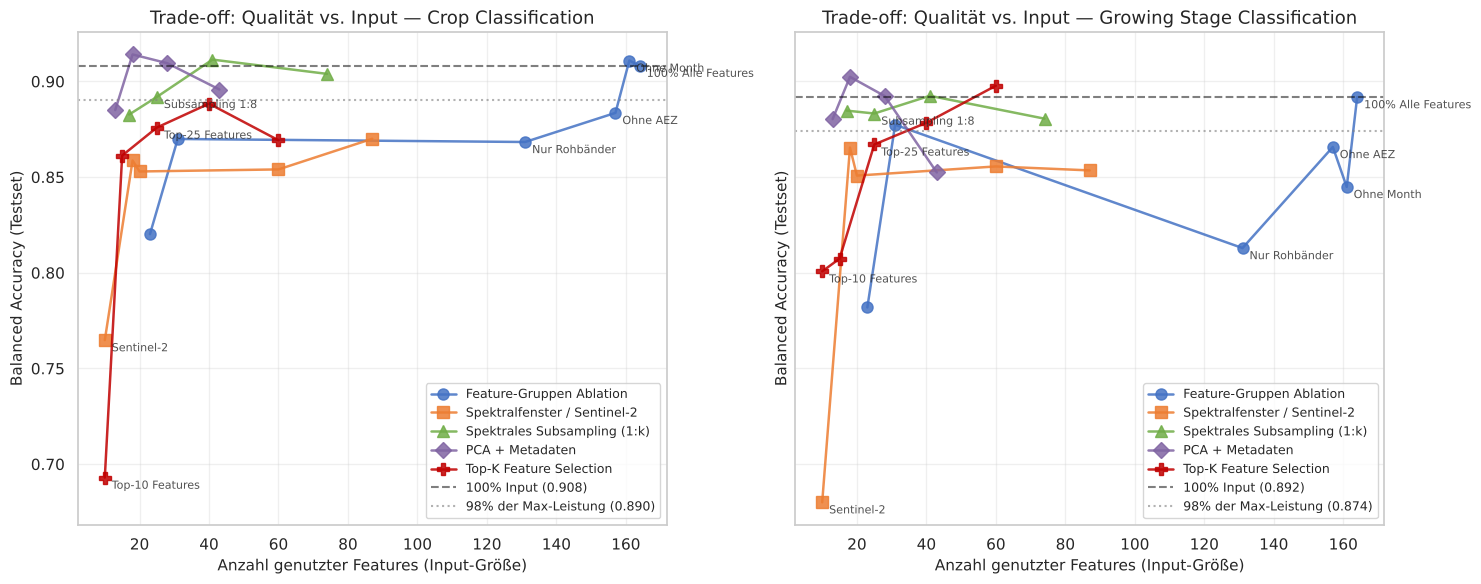

In [31]:
# Trade Off Plot
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

categories = {
    '1_Ablation': ('o', '#4472C4', 'Feature-Gruppen Ablation'),
    '2_Fenster': ('s', '#ED7D31', 'Spektralfenster / Sentinel-2'),
    '3_Subsampling': ('^', '#70AD47', 'Spektrales Subsampling (1:k)'),
    '4_PCA': ('D', '#8064A2', 'PCA + Metadaten'),
    '5_TopK_Selection': ('P', '#C00000', 'Top-K Feature Selection')
}

for ax, target_col, title in zip(axes, ['Crop_BAcc', 'Stage_BAcc'], ['Crop Classification', 'Growing Stage Classification']):
    for cat, (marker, color, label) in categories.items():
        sub = df_reduction[df_reduction['Kategorie'] == cat].sort_values('n_features')
        ax.plot(sub['n_features'], sub[target_col], marker=marker, color=color, label=label, linewidth=1.8, markersize=8, alpha=0.85)
        
        # Beschrifte ausgewählte Punkte zur besseren Lesbarkeit
        for _, row in sub.iterrows():
            if row['n_features'] in [10, 21, 25, 33, 131, 164] or 'Ohne' in row['Szenario']:
                short_lbl = row['Szenario'].split('(')[0].replace('Spektralfenster: ', '').replace('Sensor-Sim: ', '').strip()
                ax.annotate(short_lbl, (row['n_features'], row[target_col]), 
                            textcoords="offset points", xytext=(5, -8), fontsize=8, alpha=0.8)

    # 95%- und 98%-Schwelle der vollen Modellleistung einzeichnen
    full_score = df_reduction.loc[df_reduction['Szenario'].str.startswith('100%'), target_col].values[0]
    ax.axhline(full_score, color='black', linestyle='--', alpha=0.5, label=f'100% Input ({full_score:.3f})')
    ax.axhline(full_score * 0.98, color='grey', linestyle=':', alpha=0.6, label=f'98% der Max-Leistung ({full_score*0.98:.3f})')
    
    ax.set_title(f'Trade-off: Qualität vs. Input — {title}', fontsize=13)
    ax.set_xlabel('Anzahl genutzter Features (Input-Größe)', fontsize=11)
    ax.set_ylabel('Balanced Accuracy (Testset)', fontsize=11)
    ax.grid(True, alpha=0.3)
    ax.legend(loc='lower right', fontsize=9)

plt.tight_layout()
plt.show()

## Tradeoff Analyse
- Sweet Spot bei 25-35 Features: PCA 20 Komp.+ Metadaten erreicht bereits .909 und .904 mit einer Redution des Datensatzes um ca 80%
- Redundanz benachbarter Bänder: bei spektralem subsampling (nur jedes 4./8. band behalten) sinkt Precision kaum, ab 1:16 (9 Bänder) gehen Absorptionsmerkmale verloren
- Month und AEZ: Weglassen von Month kostet performance (besonders be winter_wheat), AEZ verschlechtert die Trennung von Kulturen in spezifischen Klimazonen
- Praxisrelevanz Sentinel 2 Simulation: Bei der reduktion auf 10 Bänder bleibt die Klassifikationstrefferquote hoch, besser wenn Month und AEZ

## Featrue Importance (SHAP & permutation)
1. Permutation Importance auf dem MLP-Testset: Misst wie stark die Balanced Accuracy enbricht, wenn Featrue zufällig durchmischt wird. Statt 131 Einzelbänder --> Gruppenpermutationswichtigkeit, Spektralregionen als Block durchmischen um Kollinearitätseffekte (stat. Verzerrung) auszuschalten
2. SHAP, TreeExplainer auf HistGradBoosting: Liefert exakte lokale Erklärungen --> welche Features drücken die Wahrscheinlichkeit für rice, winter_wheat oder critical nach oben/unten?

In [32]:
from sklearn.inspection import permutation_importance
import shap

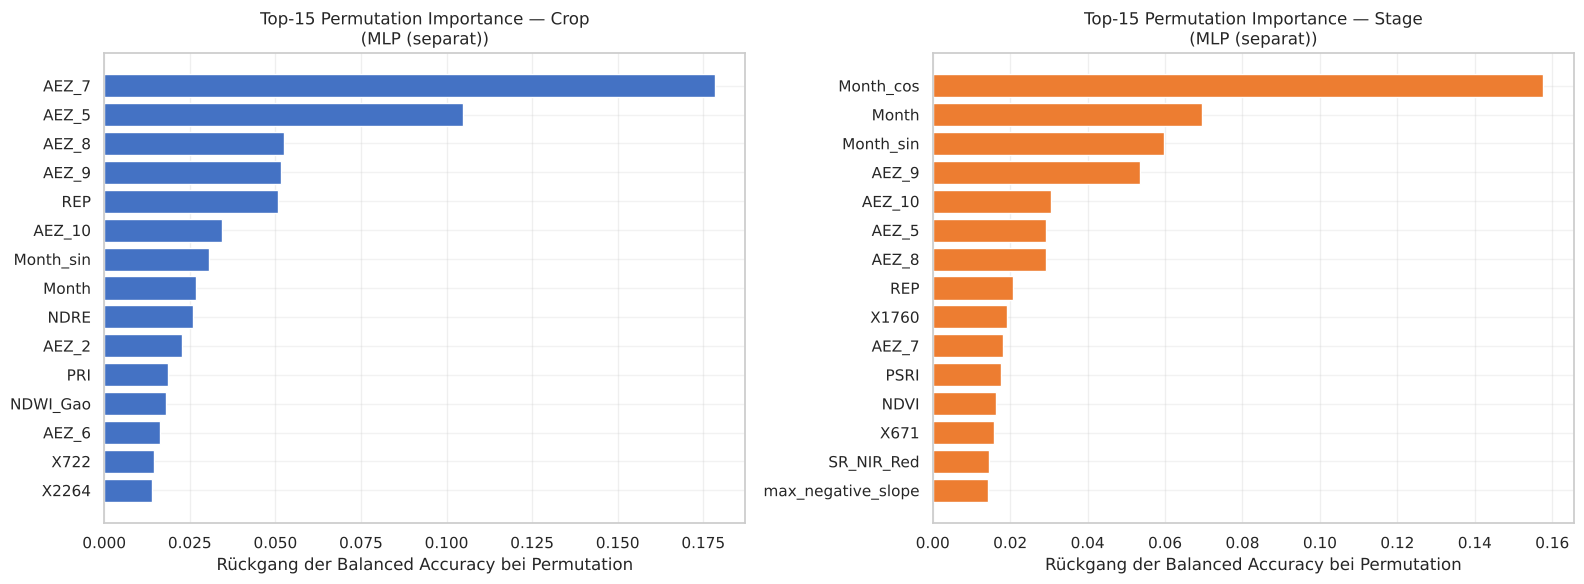

In [33]:
# Einzelfeature permutation importance auf den besten modellen
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, target_name, y_te in zip(axes, ['Crop', 'Stage'], [y_crop_test, y_stage_test]):
    info = best_per_target[target_name]
    estimator = info['best_estimator']
    is_joint = info['joint']
    
    # Custom Scorer falls Joint-Modell genutzt wird
    scorer = (make_scorer(joint_crop_bacc) if target_name == 'Crop' else make_scorer(joint_stage_bacc)) if is_joint else 'balanced_accuracy'
    y_target_te = combo_test if is_joint else y_te
    
    perm = permutation_importance(estimator, X_fe_test, y_target_te, scoring=scorer, n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
    perm_series = pd.Series(perm.importances_mean, index=X_fe_test.columns).sort_values(ascending=True)
    
    top15 = perm_series.tail(15)
    ax.barh(top15.index, top15.values, color='#4472C4' if target_name == 'Crop' else '#ED7D31')
    ax.set_title(f'Top-15 Permutation Importance — {target_name}\n({info["label"]})', fontsize=12)
    ax.set_xlabel('Rückgang der Balanced Accuracy bei Permutation')
    ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

In [34]:
# Wenn man nur 1 Band permutiert, fangen die Nachbarbänder die Info auf. 
# Deshalb permutieren wir hier ganze physikalische Spektralbereiche gleichzeitig
feature_groups = {
    'VIS_Blue_Green (400-600nm)': [c for c in usable_spec_cols if int(c[1:]) < 600],
    'VIS_Red (600-680nm)': [c for c in usable_spec_cols if 600 <= int(c[1:]) < 680],
    'Red_Edge (680-780nm)': [c for c in usable_spec_cols if 680 <= int(c[1:]) <= 780],
    'NIR_Plateau (780-1100nm)': [c for c in usable_spec_cols if 780 < int(c[1:]) <= 1100],
    'SWIR_1 (1100-1800nm)': [c for c in usable_spec_cols if 1100 < int(c[1:]) <= 1800],
    'SWIR_2 (1800-2400nm)': [c for c in usable_spec_cols if int(c[1:]) > 1800],
    'Engineered_Indices (32 Feat.)': only_fe_cols,
    'Zeitpunkt (Month)': [c for c in ['Month', 'Month_sin', 'Month_cos'] if c in X_fe_test.columns],
    'Geografie (AEZ)': aez_cols
}

group_imp_rows = []
rng = np.random.RandomState(RANDOM_STATE)

for group_name, cols in feature_groups.items():
    if not cols:
        continue
    drops = {'Gruppe': group_name, 'Anzahl_Features': len(cols)}
    for target_name, y_te in [('Crop', y_crop_test), ('Stage', y_stage_test)]:
        info = best_per_target[target_name]
        base_bacc = info['test_bacc']
        
        bacc_permuted = []
        for _ in range(5):
            X_perm = X_fe_test.copy()
            # Permutiere alle Spalten der Gruppe gemeinsam mit demselben Zeilen-Index
            perm_idx = rng.permutation(len(X_perm))
            X_perm[cols] = X_perm[cols].iloc[perm_idx].values
            pred_p = predict_target(info['best_estimator'], info['joint'], target_name, X_perm)
            bacc_permuted.append(balanced_accuracy_score(y_te, pred_p))
            
        drops[f'{target_name}_Drop_BAcc'] = base_bacc - np.mean(bacc_permuted)
    group_imp_rows.append(drops)

df_group_imp = pd.DataFrame(group_imp_rows).sort_values('Crop_Drop_BAcc', ascending=False)
display(df_group_imp.round(4))

,Gruppe,Anzahl_Features,Crop_Drop_BAcc,Stage_Drop_BAcc
8,Geografie (AEZ),7,0.5011,0.1938
5,SWIR_2 (1800-2400nm),29,0.3769,0.1793
4,SWIR_1 (1100-1800nm),40,0.2954,0.3125
6,Engineered_Indices (32 Feat.),23,0.1980,0.1637
3,NIR_Plateau (780-1100nm),28,0.1889,0.1289
2,Red_Edge (680-780nm),10,0.1191,0.0849
0,VIS_Blue_Green (400-600nm),16,0.1051,0.1448
7,Zeitpunkt (Month),3,0.0996,0.3530
1,VIS_Red (600-680nm),8,0.0838,0.0677



--- SHAP Global Feature Importance für Crop ---


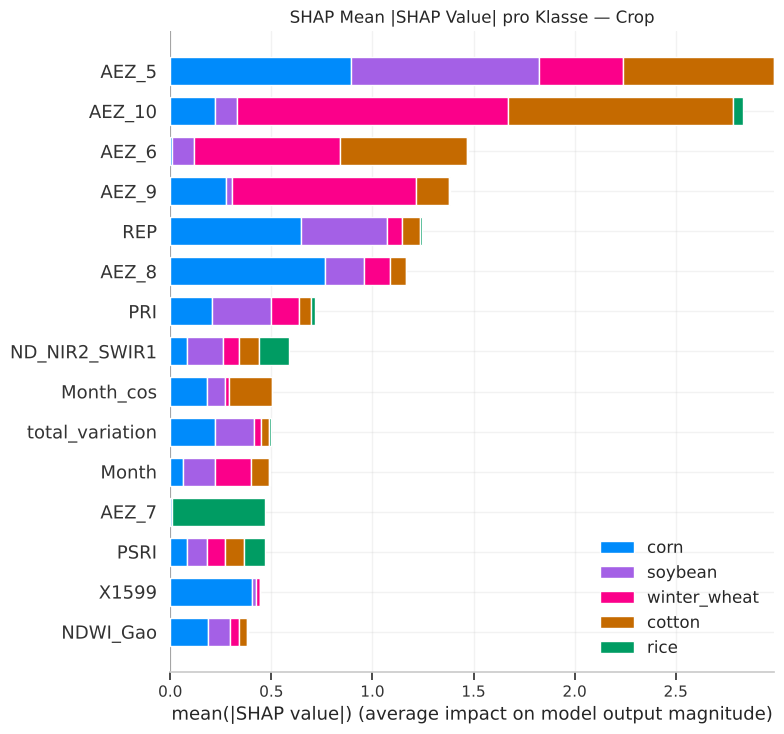


--- SHAP Global Feature Importance für Stage ---


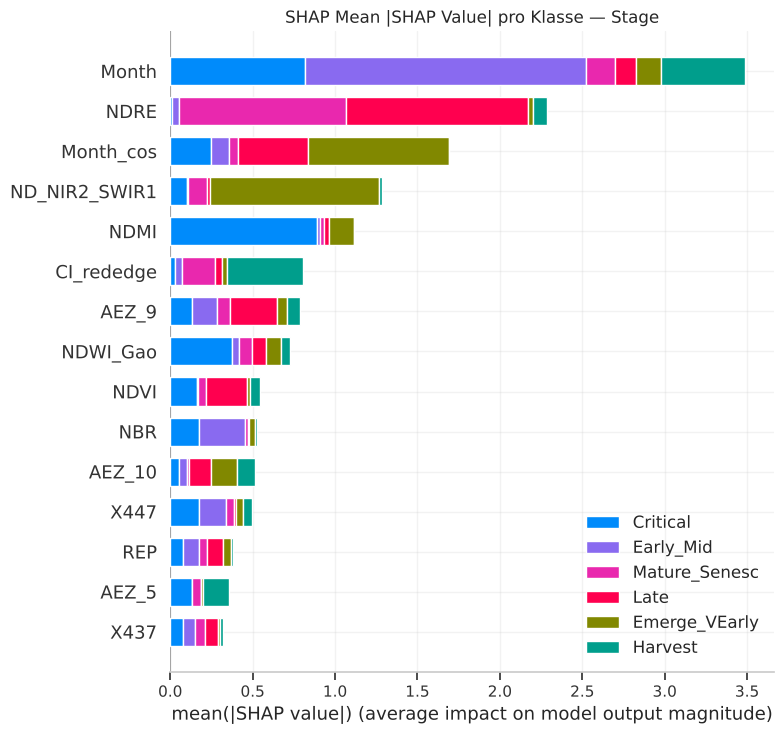

In [35]:
# TreeExplainer auf HGB ist extrem schnell und liefert exakte Shapley-Values
for target_name, class_names in [('Crop', sorted(y_crop_train.unique())), ('Stage', sorted(y_stage_train.unique()))]:
    hgb_pipe = tuned[('HistGradientBoosting', target_name)]['estimator']
    
    # Transformiere Testdaten durch Imputer + Scaler der Pipeline
    X_te_transformed = pd.DataFrame(
        hgb_pipe[:-1].transform(X_fe_test),
        columns=X_fe_test.columns,
        index=X_fe_test.index
    )
    hgb_clf = hgb_pipe.named_steps['clf']
    
    explainer = shap.TreeExplainer(hgb_clf)
    shap_values = explainer.shap_values(X_te_transformed)
    
    print(f"\n--- SHAP Global Feature Importance für {target_name} ---")
    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values, X_te_transformed, class_names=class_names, plot_type="bar", max_display=15, show=False)
    plt.title(f"SHAP Mean |SHAP Value| pro Klasse — {target_name}")
    plt.tight_layout()
    plt.show()

Die Ergebnisse der Permutations- und SHAP-Analyse lassen sich direkt durch pflanzenphysiologische, anatomische und phänologische Mechanismen aus der Hyperspektral-Fernerkundung erklären.

## Wichtigste Spektralbereiche
### Red Edge Region (680nm-750nm) und Rote Chlorophyll-Absorption (650nm-680nm)
Beobachtung im Modell: Sowohl in der SHAP-Analyse als auch bei der Permutationswichtigkeit zählen die konstruierten Red-Edge-Steigungen, Vegetationsindizes (wie NDVI und NDRE) sowie die Einzelbänder im Bereich X680 bis X750 zu den einflussreichsten Merkmalen für beide Zielgrößen (Crop und Stage).

Fachliche Begründung: Gesundes Chlorophyll absorbiert rotes Licht (~670 nm) stark für die Photosynthese, während das Schwammgewebe (Mesophyll) der Blätter durch interne Mehrfachstreuung an den Zellwänden im nahen Infrarot (>750 nm) stark reflektiert (Gates et al., 1965). Die Steigung und spektrale Position des Red-Edge-Wendepunkts (Red-Edge Inflection Point, 680–750 nm) trennt einerseits C4-Pflanzen (corn mit dichter Kranz-Anatomie und geringeren Interzellularräumen) von C3-Pflanzen (soybean, winter_wheat mit ausgeprägtem Schwammgewebe) aufgrund unterschiedlicher Blattarchitektur und Chlorophyllkonzentrationen (Aneece & Thenkabail, 2018). Andererseits ist dieser Bereich der empfindlichste Indikator für das Einsetzen der Abreife (Mature_Senesc), da der altersbedingte Chlorophyllabbau eine Verschiebung der Red-Edge zu kürzeren Wellenlängen bewirkt (sog. Red-Edge Blue-Shift; Horler et al., 1983; Gitelson et al., 1996).


C3- und C4-Pflanzen beschreiben zwei verschiedene biochemische Stoffwechselwege, die Pflanzen bei der Photosynthese nutzen, um Kohlenstoffdioxid (CO2) aus der Luft zu binden und in Zucker (Biomasse) umzuwandeln.Der Name leitet sich einfach davon ab, wie viele Kohlenstoffatome das allererste stabile Molekül hat, das bei der CO2-Fixierung entsteht (3 Kohlenstoffatome bei C3 vs. 4 Kohlenstoffatome bei C4).

### Nahinfrarot Plateau (nir, 780-1100nm)
Beobachtung im Modell: Die NIR-Bänder sowie die spektrale Gesamtintensität (spectral_sum) zeigen eine besonders hohe Relevanz bei der Unterscheidung der Wachstumsstadien (Stage).

Fachliche Begründung: Im NIR-Plateau wird die Reflexion primär durch die interne Blattstruktur sowie die Bestandsarchitektur (Blattflächenindex / Leaf Area Index, LAI) bestimmt (Gates et al., 1965; Aneece & Thenkabail, 2018). Ein geschlossenes, vitales Blätterdach während der Hauptwachstumsphasen (Early_Mid, Critical) führt durch Mehrfachstreuung zu hohen NIR-Reflexionswerten (45–55 %), wohingegen keimende Bestände (Emerge_VEarly) oder abgeerntete Flächen (Harvest) durch das flache, deutlich niedrigere Reflexionsprofil offenen Bodens dominiert werden (Aneece & Thenkabail, 2018)

### Kurzwelliges Infrarot (swir 1/2 1400nm-2350nm)
Beobachtung im Modell: Bänder oberhalb von 1400 nm sowie die Wasser- und Seneszenz-Indizes weisen hohe klassenspezifische SHAP-Werte für rice, cotton sowie die späten Reifestadien (Mature_Senesc, Harvest) auf.

Fachliche Begründung: Das SWIR-Spektrum wird maßgeblich durch flüssiges Blattwasser (starke Wasserabsorptionsbanden nahe 1450 nm und 1940 nm; Gao, 1996) sowie durch trockene Strukturkohlenhydrate wie Zellulose und Lignin (>2000 nm; Daughtry et al., 2004) gesteuert. Reis (rice) zeigt in der EDA und im Modell extrem niedrige SWIR-Reflexionswerte (<15 %), da das stehende Wasser auf gefluteten Reisfeldern die einfallende SWIR-Strahlung nahezu vollständig absorbiert (Aneece & Thenkabail, 2018). Umgekehrt führen der sinkende Blattwassergehalt bei fortschreitender Abreife (Mature_Senesc, Harvest) sowie die trockenmasse- und faserreichen Bestände von Baumwolle (cotton) zu einer stark erhöhten SWIR-Reflexion (Daughtry et al., 2004; Aneece & Thenkabail, 2018).

## Wichtigste Zeiträume und "Lag Effekte"
### Phänologische Phasenverschiebung
Beobachtung im Modell: Das Merkmal Month erweist sich sowohl für Crop (insbesondere zur Abgrenzung von winter_wheat) als auch für Stage als eines der stärksten Einzelmerkmale im gesamten Modell.

Fachliche Begründung: Landwirtschaftliche Kulturen folgen einem festen phänologischen Jahreszyklus (Wardlow et al., 2007). Insbesondere Winterweizen (winter_wheat) weist einen antizyklischen Wachstumskalender gegenüber den Sommerkulturen (corn, soybean, cotton) auf: Während Sommerkulturen im Frühjahr (Month 5) auflaufen (Emerge_VEarly) und im Hochsommer (Month 7–8) ihre kritische Reproduktionsphase (Critical) erreichen, befindet sich Winterweizen im Frühsommer bereits in der Abreife (Mature_Senesc) und wird erst im Herbst (Month 9–10) neu ausgesät (Emerge_VEarly; Wardlow et al., 2007; Aneece & Thenkabail, 2018).

### Spektral Temporärer Lag-Effekt (Klima und Standortbedingter Wachstumsversatz)
Beobachtung im Modell: In der Datenreduktionsstudie führt das alleinige Verwenden von Month ohne spektrale Indizes – ebenso wie das Weglassen der agroökologischen Zonen (AEZ) – zu einem deutlichen Performanceverlust bei den Wachstumsstadien (Stage).

Fachliche Begründung: Zwischen dem kalendarischen Aufnahmemonat (Month) und dem tatsächlichen biologischen Entwicklungsstadium (Stage) besteht ein standort- und witterungsabhängiger zeitlicher Versatz (phänologischer Lag-Effekt; Reed et al., 1994). Abhängig vom Temperaturniveau (Wachstumsgradtage / Growing Degree Days), der Wasserverfügbarkeit und dem Aussaattermin in unterschiedlichen agroökologischen Zonen (AEZ) erreicht dieselbe Kulturpflanze ein bestimmtes Stadium zu unterschiedlichen Zeitpunkten (z. B. befindet sich Mais in wärmeren Zonen im Juli bereits im Stadium Late, während er in kühleren Zonen im selben Monat noch in Early_Mid oder Critical steht; Reed et al., 1994; Aneece & Thenkabail, 2018). Das Modell nutzt Month und AEZ daher als zeitlich-geografische A-priori-Wahrscheinlichkeit und korrigiert den phänologischen Lag über die spektralen Chlorophyll- und Wasserindizes.

### Literatur
Aneece, I., & Thenkabail, P. S. (2018). Accuracies achieved in classifying five leading world crop types and their growth stages using optimal Earth Observing-1 Hyperion hyperspectral narrowbands on Google Earth Engine. Remote Sensing, 10(12), 2027. https://doi.org/10.3390/rs10122027

Daughtry, C. S. T., Hunt, E. R., & McMurtrey, J. E. (2004). Assessing crop residue cover byenz spectral reflectance. Remote Sensing of Environment, 90(1), 126–134. https://doi.org/10.1016/j.rse.2003.10.023

Gao, B.-C. (1996). NDWI—A normalized difference water index for remote sensing of vegetation liquid water from space. Remote Sensing of Environment, 58(3), 257–266. https://doi.org/10.1016/S0034-4257(96)00067-3

Gates, D. M., Keegan, H. J., Schleter, J. C., & Weidner, V. R. (1965). Spectral properties of plants. Applied Optics, 4(1), 11–20. https://doi.org/10.1364/AO.4.000011

Gitelson, A. A., Merzlyak, M. N., & Lichtenthaler, H. K. (1996). Detection of red edge position and chlorophyll content by reflectance measurements near 700 nm. Journal of Plant Physiology, 148(3–4), 501–508. https://doi.org/10.1016/S0176-1617(96)80285-9

Horler, D. N. H., Dockray, M., & Barber, J. (1983). The red edge of plant leaf reflectance. International Journal of Remote Sensing, 4(2), 273–288. https://doi.org/10.1080/01431168308948546

Reed, B. C., Brown, J. F., VanderZee, D., Loveland, T. R., Merchant, J. W., & Ohlen, D. O. (1994). Measuring phenological variability from satellite imagery. Journal of Vegetation Science, 5(5), 703–714. https://doi.org/10.2307/3235884

Wardlow, B. D., Egbert, S. L., & Kastens, J. H. (2007). Analysis of time-series MODIS 250 m vegetation index data for crop classification in the U.S. Central Great Plains. Remote Sensing of Environment, 108(3), 290–310. https://doi.org/10.1016/j.rse.2006.11.021

# Finale Vorhersage auf dem Validierungsdatensatz (`data/test.csv`)

Für die Abgabe sagen wir `Crop` und `Stage` für die ungelabelten Zeilen in `data/test.csv` vorher.

**Modell: MLP mit gemeinsamem Label `Crop|Stage` für beide Zielgrößen.** Ein einziges Modell sagt die Kombination vorher, die Vorhersage wird am `|` in Crop und Stage zerlegt. Begründung:
- In der CV liegen gemeinsames und separates MLP praktisch gleichauf (Tabelle *Strategievergleich*, Unterschiede im Bereich der CV-Streuung). Die automatische Auswahl oben (`best_per_target`) nimmt einfach den höchsten CV-Wert und ist bei so kleinen Abständen nicht aussagekräftig.
- Auf dem Testsplit schneidet das gemeinsame MLP bei Crop und Stage mindestens gleich gut ab (Tabelle *Alle getunten Kandidaten auf dem Test-Split*).
- Das gemeinsame Modell gibt nur Kombinationen aus, die im Training vorkommen (23 von 30 möglichen). Zwei separate Modelle können unmögliche Paare wie `rice|Harvest` erzeugen. Wie oft das auf dem Testsplit passiert, zeigt die nächste Zelle.

**Training auf 100 % der Trainingsdaten.** Train/Test-Split und CV dienten der Modell- und Hyperparameterwahl und der Leistungsschätzung. Für die Abgabe werden die getunten Hyperparameter des gemeinsamen MLP übernommen (`clone` kopiert die Parameter, nicht die gelernten Gewichte) und das Modell einmal auf allen gelabelten Zeilen neu gefittet, ohne erneutes Tuning. Mehr Daten helfen vor allem den kleinen Klassen (`rice`, `cotton|Harvest`). Als Leistungsschätzung gilt weiterhin der Wert auf dem Testsplit oben (eher konservativ, da nur mit 70 % der Daten trainiert).

**Vorverarbeitung:** identisch zum Training über `process_dataframe` aus `pipeline/src/data_prep.py` (zeilenweise Interpolation, Feature Engineering, One-Hot-AEZ mit den AEZ-Kategorien des Trainings). Danach werden die Spalten exakt in die Reihenfolge der Trainings-Features gebracht.

In [36]:
# Konsistenz-Check auf dem Testsplit: Wie oft ergeben zwei separate Modelle eine Crop|Stage-Kombination, die es im Training nicht gibt?
valid_combos = set(combo_train)
sep_combo = pd.Series(tuned[('MLP', 'Crop')]['estimator'].predict(X_fe_test)) + '|' + pd.Series(tuned[('MLP', 'Stage')]['estimator'].predict(X_fe_test))
joint_combo = pd.Series(tuned[('MLP', 'Joint')]['estimator'].predict(X_fe_test))

for name, pairs in [('Separate MLPs', sep_combo), ('Gemeinsames MLP', joint_combo)]:
    invalid = ~pairs.isin(valid_combos)
    print(f'{name}: {invalid.sum()} von {len(pairs)} Vorhersagen ({invalid.mean():.1%}) sind unmögliche Kombinationen')
sep_combo[~sep_combo.isin(valid_combos)].value_counts()

Separate MLPs: 12 von 1678 Vorhersagen (0.7%) sind unmögliche Kombinationen
Gemeinsames MLP: 0 von 1678 Vorhersagen (0.0%) sind unmögliche Kombinationen


winter_wheat|Early_Mid    7
rice|Critical             5
Name: count, dtype: int64

In [37]:
import sys
sys.path.insert(0, 'pipeline')
from src.data_prep import process_dataframe

raw_train = pd.read_csv('data/train.csv')
raw_test = pd.read_csv('data/test.csv')

# Gleiche Vorverarbeitung wie im Training; AEZ-Kategorien aus dem Training, damit die One-Hot-Spalten übereinstimmen
test_processed = process_dataframe(raw_test, aez_categories=raw_train['AEZ'].dropna().unique())
missing_cols = set(X_fe_train.columns) - set(test_processed.columns)
assert not missing_cols, f'Im Testset fehlen Feature-Spalten: {missing_cols}'

X_submit = test_processed[X_fe_train.columns]
assert len(X_submit) == len(raw_test) and X_submit.notna().all().all()
print(f'Validierungsdaten: {X_submit.shape[0]} Zeilen, {X_submit.shape[1]} Features (gleiche Spalten und Reihenfolge wie im Training)')

Validierungsdaten: 1397 Zeilen, 164 Features (gleiche Spalten und Reihenfolge wie im Training)


In [38]:
# Getunte Hyperparameter des gemeinsamen MLP übernehmen und auf 100 % der Trainingsdaten neu fitten
final_model = clone(tuned[('MLP', 'Joint')]['estimator'])
final_model.fit(df[X_fe_train.columns], df['Crop_Stage'])

print('Hyperparameter:', tuned[('MLP', 'Joint')]['params'])
print(f"Trainiert auf {len(df)} Zeilen ({df['Crop_Stage'].nunique()} Klassen), {final_model.named_steps['clf'].n_iter_} Epochen")

Hyperparameter: {'clf__alpha': np.float64(0.04467752817973906), 'clf__batch_size': 200, 'clf__early_stopping': True, 'clf__hidden_layer_sizes': (512, 256), 'clf__learning_rate_init': np.float64(0.001096821720752952), 'clf__max_iter': 1000}
Trainiert auf 5591 Zeilen (23 Klassen), 29 Epochen


In [39]:
pred_crop, pred_stage = split_joint(final_model.predict(X_submit))

# Crop und Stage an denselben Positionen wie in train.csv einfügen, alle anderen Spalten bleiben unverändert
submission = raw_test.copy()
submission.insert(raw_train.columns.get_loc('Crop'), 'Crop', pred_crop)
submission.insert(raw_train.columns.get_loc('Stage'), 'Stage', pred_stage)
assert list(submission.columns) == list(raw_train.columns)
assert submission[['Crop', 'Stage']].notna().all().all()
assert (submission['Crop'] + '|' + submission['Stage']).isin(valid_combos).all()

SUBMISSION_PATH = 'test_predictions.csv'
submission.rename(columns={'Unnamed: 0': ''}).to_csv(SUBMISSION_PATH, index=False)
assert pd.read_csv(SUBMISSION_PATH).drop(columns=['Crop', 'Stage']).equals(raw_test)
print(f'{len(submission)} Vorhersagen gespeichert in {SUBMISSION_PATH}')

# Plausibilität: vorhergesagte Klassenverteilung im Vergleich zur Trainingsverteilung
for target in ['Crop', 'Stage']:
    display(pd.DataFrame({'Training': df[target].value_counts(normalize=True),
                          'Vorhersage': submission[target].value_counts(normalize=True)}).round(3))
pd.crosstab(submission['Crop'], submission['Stage'])

1397 Vorhersagen gespeichert in test_predictions.csv


,Training,Vorhersage
Crop,,
corn,0.375,0.377
soybean,0.299,0.301
winter_wheat,0.192,0.188
cotton,0.118,0.122
rice,0.017,0.013


,Training,Vorhersage
Stage,,
Critical,0.276,0.270
Early_Mid,0.176,0.178
Emerge_VEarly,0.186,0.195
Harvest,0.032,0.031
Late,0.154,0.153
Mature_Senesc,0.177,0.173


Stage,Critical,Early_Mid,Emerge_VEarly,Harvest,Late,Mature_Senesc
Crop,,,,,,
corn,177,49,35,28,141,96
cotton,36,74,48,5,0,8
rice,0,11,0,0,7,0
soybean,151,115,31,10,59,54
winter_wheat,13,0,159,0,7,83
